# RFPP Kelompok 5 — Eksplorasi data & plot evaluasi

**Fusi tingkat fitur: citra RGB (20-D) + e-nose (8-D) → 28-D, klasifikasi biner daging sapi segar/busuk.**

Notebook ini **hanya membaca** berkas yang sudah ada:

| Sumber | Isi |
|---|---|
| `results/*.csv` | keluaran F5 (evaluasi), F5b (probe), F5c (importance) |
| `cache/features/*.parquet` | fitur visual 20-D dan kanal sensor 8-D teragregasi per menit |
| `data/manifest.json` | audit data mentah, trajektori, keputusan batas kelas |
| `config.yaml` | konfigurasi beku (seed, model, split, label) |

Tidak ada satu pun model yang dilatih ulang di sini, jadi angka di notebook ini
**identik** dengan angka di `results/`. Semua gambar juga disimpan ke `figures/`
untuk dipakai di laporan (F6).

**Cara menjalankan:** kernel `Python (RFPP)` → *Run All*. Bila kernel belum ada:

```powershell
cd "D:\Documents\S2\Kuliah\261\RFPP"
.\.venv\Scripts\python.exe -m ipykernel install --user --name rfpp --display-name "Python (RFPP)"
```

> **Baca dulu sebelum menyalin angka ke laporan.** Skor 0,95–0,998 di sini **bukan**
> akurasi deteksi pembusukan di dunia nyata. Kedua dataset adalah **satu trajektori
> waktu** dengan label = segmen waktu yang berurutan, sehingga split blok waktu
> masih menyisakan *interpolasi temporal* dan *konfound waktu*. Bagian 8 merangkum
> batas klaim yang wajib ditulis.

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display
from PIL import Image
from scipy.stats import binomtest

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.load_data import read_config, _visual_timestamp
from src.features_visual import preprocess
from src.protocol import fold_splits

cfg = read_config()
RES = ROOT / cfg["paths"]["results"]
FIG = ROOT / cfg["paths"]["figures"]
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "axes.unicode_minus": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 9,
})

WARNA = {"visual": "#2a7fbf", "sensor": "#d1495b", "fused": "#2e8b57"}
KELAS = {"fresh": "#2a7fbf", "spoiled": "#d1495b"}
ARAH = {"segar-busuk": "#6a4c93", "busuk-segar": "#f4a259"}
MODEL = ["random_forest", "svm_rbf", "knn", "mlp"]
SET = ["visual", "sensor", "fused"]
LABEL_MODEL = {"random_forest": "Random Forest", "svm_rbf": "SVM (RBF)", "knn": "k-NN", "mlp": "MLP"}
LABEL_SET = {"visual": "Visual (20-D)", "sensor": "Sensor (8-D)", "fused": "Fused (28-D)"}
LABEL_KELAS = {"fresh": "segar", "spoiled": "busuk"}

TERSIMPAN = []


def tampil(fig, nama):
    path = FIG / f"{nama}.png"
    fig.savefig(path, bbox_inches="tight")
    TERSIMPAN.append(path)
    display(fig)
    plt.close(fig)
    return path


metrics = pd.read_csv(RES / "metrics.csv")
summary = pd.read_csv(RES / "summary.csv")
conf = pd.read_csv(RES / "confusion.csv")
delta = pd.read_csv(RES / "paired_delta.csv")
probe = pd.read_csv(RES / "probe.csv")
probe_sum = pd.read_csv(RES / "probe_summary.csv")
imp = pd.read_csv(RES / "importance.csv")
imp_sum = pd.read_csv(RES / "importance_summary.csv")
imp_top = pd.read_csv(RES / "importance_top10.csv")
imp_feat = pd.read_csv(RES / "importance_per_feature.csv")

vis = pd.read_parquet(ROOT / cfg["paths"]["cache_visual"])
sen = pd.read_parquet(ROOT / cfg["paths"]["cache_sensor"])
manifest = json.loads((ROOT / cfg["paths"]["manifest"]).read_text(encoding="utf-8"))

V = sorted(c for c in vis.columns if c.startswith("f"))
S = list(cfg["sensor"]["channels"])
assert len(V) + len(S) == cfg["fusion"]["expected_dim"], "dimensi fused tidak sesuai config"

# 12 konfigurasi inti (3 set fitur x 4 model); varian scaling hanya untuk fused
core = summary[summary.scaling == "standard"].copy()
conf_core = conf[conf.scaling == "standard"].copy()

hb = cfg["visual"]["hist_bins"]
NAMA_FITUR, i = {}, 0
for ch, n in [("H", hb["h"]), ("S", hb["s"]), ("V", hb["v"])]:
    for b in range(n):
        NAMA_FITUR[f"f{i:02d}"] = f"{ch} bin {b + 1}"
        i += 1
for p in cfg["visual"]["glcm"]["properties"]:
    NAMA_FITUR[f"f{i:02d}"] = f"GLCM {p}"
    i += 1

print(f"ROOT           : {ROOT}")
print(f"visual cache   : {vis.shape[0]} baris x {len(V)} fitur")
print(f"sensor cache   : {sen.shape[0]} baris x {len(S)} kanal")
print(f"fused          : {len(V) + len(S)}-D  (config: {cfg['fusion']['expected_dim']})")
print(f"metrics.csv    : {len(metrics)} baris = {len(core)} konfigurasi x "
      f"{len(cfg['protocol']['pairing_seeds'])} seed x {cfg['protocol']['n_folds']} fold + varian scaling")
print(f"konfigurasi inti: {len(core)}")

ROOT           : D:\Documents\S2\Kuliah\261\RFPP
visual cache   : 1872 baris x 20 fitur
sensor cache   : 1735 baris x 8 kanal
fused          : 28-D  (config: 28)
metrics.csv    : 350 baris = 12 konfigurasi x 5 seed x 5 fold + varian scaling
konfigurasi inti: 12


## 1. Inventaris data

Dua modalitas yang **tidak** berasal dari objek yang sama: sensor dari Mendeley
(`n8mc3nspfn`, e-nose 8 kanal MQ), visual dari Kaggle (`crowww/meat-quality-assessment-based-on-deep-learning`,
kamera IP). Keduanya CC BY 4.0. Karena itu pasangan fused dibentuk **di dalam fold**
secara acak tanpa pengembalian, bukan pencocokan sampel fisik yang sama.

In [2]:
inv = pd.DataFrame([
    {
        "modalitas": "visual (citra)",
        "baris_dipakai": len(vis),
        "segar": int((vis.label == "fresh").sum()),
        "busuk": int((vis.label == "spoiled").sum()),
        "blok_waktu": int(vis.group_id.nunique()),
        "dimensi": len(V),
        "sumber": "Kaggle crowww",
    },
    {
        "modalitas": "sensor (e-nose)",
        "baris_dipakai": len(sen),
        "segar": int((sen.label == "fresh").sum()),
        "busuk": int((sen.label == "spoiled").sum()),
        "blok_waktu": int(sen.group_id.nunique()),
        "dimensi": len(S),
        "sumber": "Mendeley n8mc3nspfn",
    },
])
display(inv)

print("Blok waktu per kelas:")
display(pd.DataFrame({
    "visual": vis.groupby("label").group_id.nunique(),
    "sensor": sen.groupby("label").group_id.nunique(),
}).rename(index=LABEL_KELAS))

print("\nTrajektori visual (dari nama berkas, EXIF kosong):")
display(pd.DataFrame(manifest["visual"]["trajectory"]).T)

print("\nBatas kelas visual:")
display(pd.DataFrame({
    "aturan": manifest["visual"]["boundary"]["rule"],
    "frame_dibuang": manifest["visual"]["boundary"]["dibuang"],
    "dibuang_per_kelas": str(manifest["visual"]["boundary"]["dibuang_per_kelas"]),
    "frame_terakhir_segar": manifest["visual"]["boundary"]["frame_terakhir_kelas_awal"],
    "frame_pertama_busuk": manifest["visual"]["boundary"]["frame_pertama_kelas_akhir"],
}, index=["nilai"]).T)

print("\nSensor: kelas biner =", cfg["sensor"]["class_map"],
      "| alasan:", cfg["sensor"]["class_map_reason"])
print("Sensor: kolom dibuang =", cfg["sensor"]["excluded_columns"])
print(f"Sensor: {manifest['sensor']['rows_raw']} baris mentah -> "
      f"{manifest['sensor']['rows_aggregated']} baris (rata-rata per menit), "
      f"sha256 cocok penerbit = {manifest['sensor']['sha256_cocok_penerbit']}")

,modalitas,baris_dipakai,segar,busuk,blok_waktu,dimensi,sumber
0,visual (citra),1872,939,933,128,20,Kaggle crowww
1,sensor (e-nose),1735,625,1110,58,8,Mendeley n8mc3nspfn


Blok waktu per kelas:


,visual,sensor
label,,
segar,64,21
busuk,64,38



Trajektori visual (dari nama berkas, EXIF kosong):


,n,mulai,selesai,interval_menit_modus,sesi
fresh,948,2017-10-16 10:43:21,2017-10-17 18:59:21,2.0,1
spoiled,948,2017-10-17 19:01:21,2017-10-19 03:09:21,2.0,1



Batas kelas visual:


,nilai
aturan,drop_adjacent_blocks
frame_dibuang,24
dibuang_per_kelas,"{'spoiled': 15, 'fresh': 9}"
frame_terakhir_segar,2017-10-17 18:59:21
frame_pertama_busuk,2017-10-17 19:01:21



Sensor: kelas biner = {'fresh': [1, 2, 3], 'spoiled': [4]} | alasan: Opsi A, keputusan kelompok 2026-11-11: TVC<5 vs TVC>=5 (batas spoiled penerbit)
Sensor: kolom dibuang = ['sl no', 'minutes', 'Temperature', 'Humidity', 'tvc', 'class']
Sensor: 20815 baris mentah -> 1735 baris (rata-rata per menit), sha256 cocok penerbit = True


## 2. EDA sensor (e-nose)

Sumbu-x adalah **menit ke-** sejak awal perekaman (`sensor_id`), bukan nomor baris acak.
Garis putus-putus = batas kelas; area abu-abu = blok 30 menit yang memuat **dua kelas**.

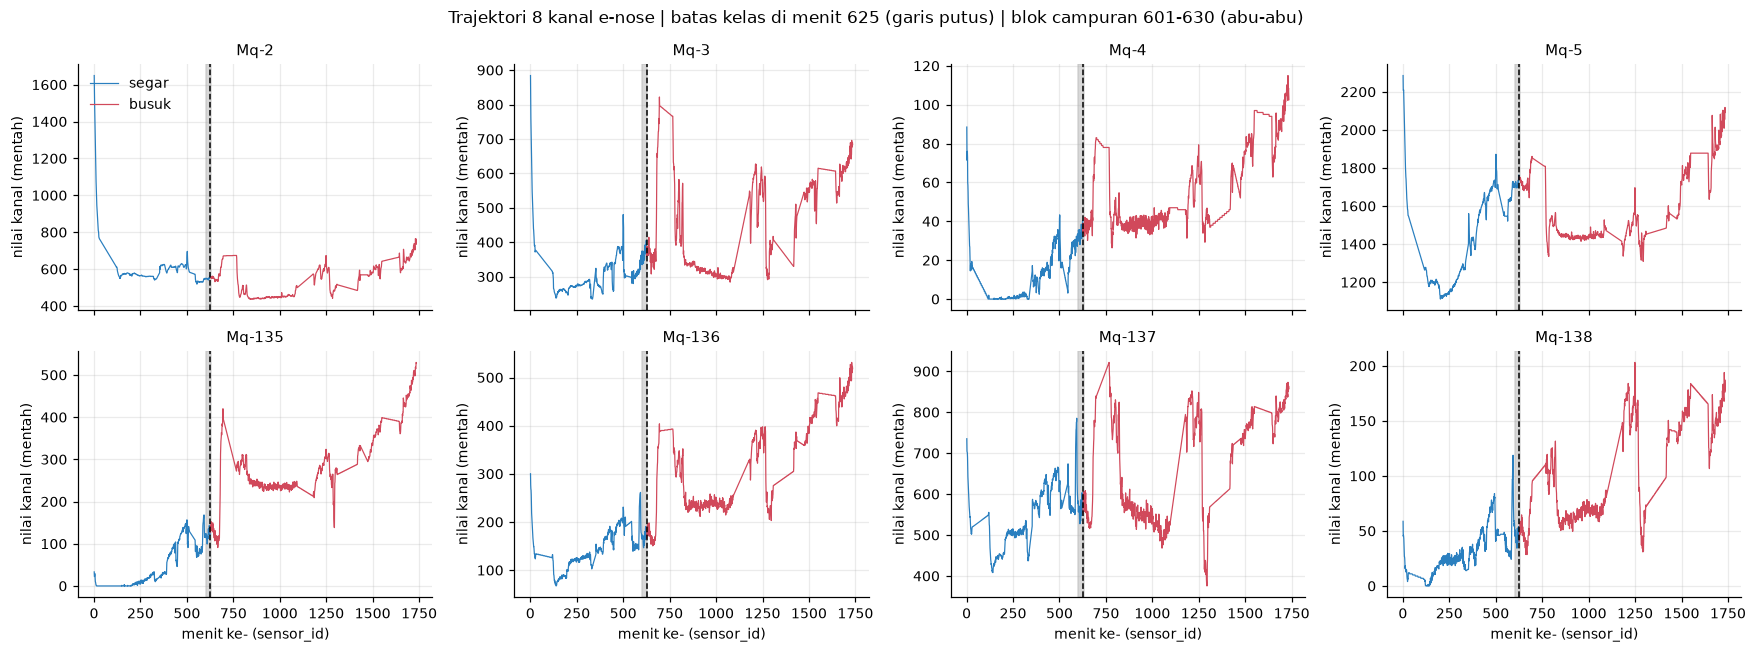

WindowsPath('D:/Documents/S2/Kuliah/261/RFPP/figures/01_sensor_trajektori.png')

In [3]:
batas_sensor = int(sen.loc[sen.label == "fresh", "sensor_id"].max())
campur = sen.groupby("group_id").label.nunique()
blok_campur = sorted(campur[campur > 1].index.tolist())
rentang_campur = (
    int(sen.loc[sen.group_id.isin(blok_campur), "sensor_id"].min()),
    int(sen.loc[sen.group_id.isin(blok_campur), "sensor_id"].max()),
)

fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex=True)
for ax, ch in zip(axes.ravel(), S):
    ax.axvspan(*rentang_campur, color="0.75", alpha=0.6, zorder=0)
    for lab in ["fresh", "spoiled"]:
        d = sen[sen.label == lab]
        ax.plot(d.sensor_id, d[ch], lw=0.8, color=KELAS[lab], label=LABEL_KELAS[lab])
    ax.axvline(batas_sensor + 0.5, color="k", ls="--", lw=1)
    ax.set_title(ch, fontsize=10)
    ax.set_ylabel("nilai kanal (mentah)")
axes[0, 0].legend(loc="upper left", frameon=False)
for ax in axes[-1]:
    ax.set_xlabel("menit ke- (sensor_id)")
fig.suptitle(
    f"Trajektori 8 kanal e-nose | batas kelas di menit {batas_sensor} "
    f"(garis putus) | blok campuran {rentang_campur[0]}-{rentang_campur[1]} (abu-abu)",
    fontsize=11,
)
fig.tight_layout()
tampil(fig, "01_sensor_trajektori")

### 2.1 Temuan: blok batas sensor **tidak** dibuang

Pada visual, dua blok yang bersebelahan dengan titik pergantian label dibuang
(24 frame: 9 segar + 15 busuk) karena frame yang berjarak 2 menit hampir identik
tetapi berlabel lawan. **Aturan yang sama tidak diterapkan pada sensor**: blok
30 menit yang melintasi batas kelas masih dipakai utuh.

Yang perlu dibedakan dengan jujur:

* **Bukan kebocoran antar-fold.** `StratifiedGroupKFold` memindahkan satu blok
  secara utuh ke latih *atau* uji, jadi tidak ada menit dari blok yang sama
  muncul di kedua sisi. Ini diverifikasi ulang di sel bawah dan diuji di
  `tests/test_protocol.py`.
* **Tetapi ada ambiguitas label di dalam blok.** Menit-menit tepat di sekitar
  pergantian kelas adalah periode transisi pembusukan; labelnya dipaksakan
  biner oleh `class_map`. Ini menambah derau label, bukan menghapusnya.

Konsekuensi untuk laporan: tulis sebagai **keterbatasan protokol**, atau
setujui penghapusan blok batas sensor lalu jalankan ulang F5–F5c. Angka di
notebook ini memakai cache apa adanya (blok campuran **dipakai**).

In [4]:
rincian = []
for g in blok_campur:
    d = sen[sen.group_id == g]
    vc = d.label.value_counts()
    rincian.append({
        "group_id": g,
        "menit_awal": int(d.sensor_id.min()),
        "menit_akhir": int(d.sensor_id.max()),
        "menit_segar": int(vc.get("fresh", 0)),
        "menit_busuk": int(vc.get("spoiled", 0)),
    })
display(pd.DataFrame(rincian))

splits = fold_splits(cfg, vis, sen)
cek = []
for k, (v_tr, v_te, s_tr, s_te) in enumerate(splits, start=1):
    gv_tr, gv_te = set(vis.iloc[v_tr].group_id), set(vis.iloc[v_te].group_id)
    gs_tr, gs_te = set(sen.iloc[s_tr].group_id), set(sen.iloc[s_te].group_id)
    cek.append({
        "fold": k,
        "irisan_blok_visual": len(gv_tr & gv_te),
        "irisan_blok_sensor": len(gs_tr & gs_te),
        "blok_campur_di_sisi": "latih" if set(blok_campur) & gs_tr else "uji",
        "menit_sensor_uji": len(s_te),
        "frame_visual_uji": len(v_te),
    })
cek = pd.DataFrame(cek)
display(cek)
assert cek.irisan_blok_visual.sum() == 0 and cek.irisan_blok_sensor.sum() == 0
print("OK: tidak ada blok waktu yang muncul di latih dan uji sekaligus (kedua modalitas).")
print(f"Total frame visual dibuang di batas : {manifest['visual']['boundary']['dibuang']}")
print(f"Total menit sensor dibuang di batas: 0 (aturan boundary hanya ada di config visual)")

,group_id,menit_awal,menit_akhir,menit_segar,menit_busuk
0,20,601,630,25,5


,fold,irisan_blok_visual,irisan_blok_sensor,blok_campur_di_sisi,menit_sensor_uji,frame_visual_uji
0,1,0,0,latih,355,382
1,2,0,0,uji,360,369
2,3,0,0,latih,330,372
3,4,0,0,latih,330,368
4,5,0,0,latih,360,381


OK: tidak ada blok waktu yang muncul di latih dan uji sekaligus (kedua modalitas).
Total frame visual dibuang di batas : 24
Total menit sensor dibuang di batas: 0 (aturan boundary hanya ada di config visual)


### 2.2 Sebaran kanal per kelas dan korelasi antar-kanal

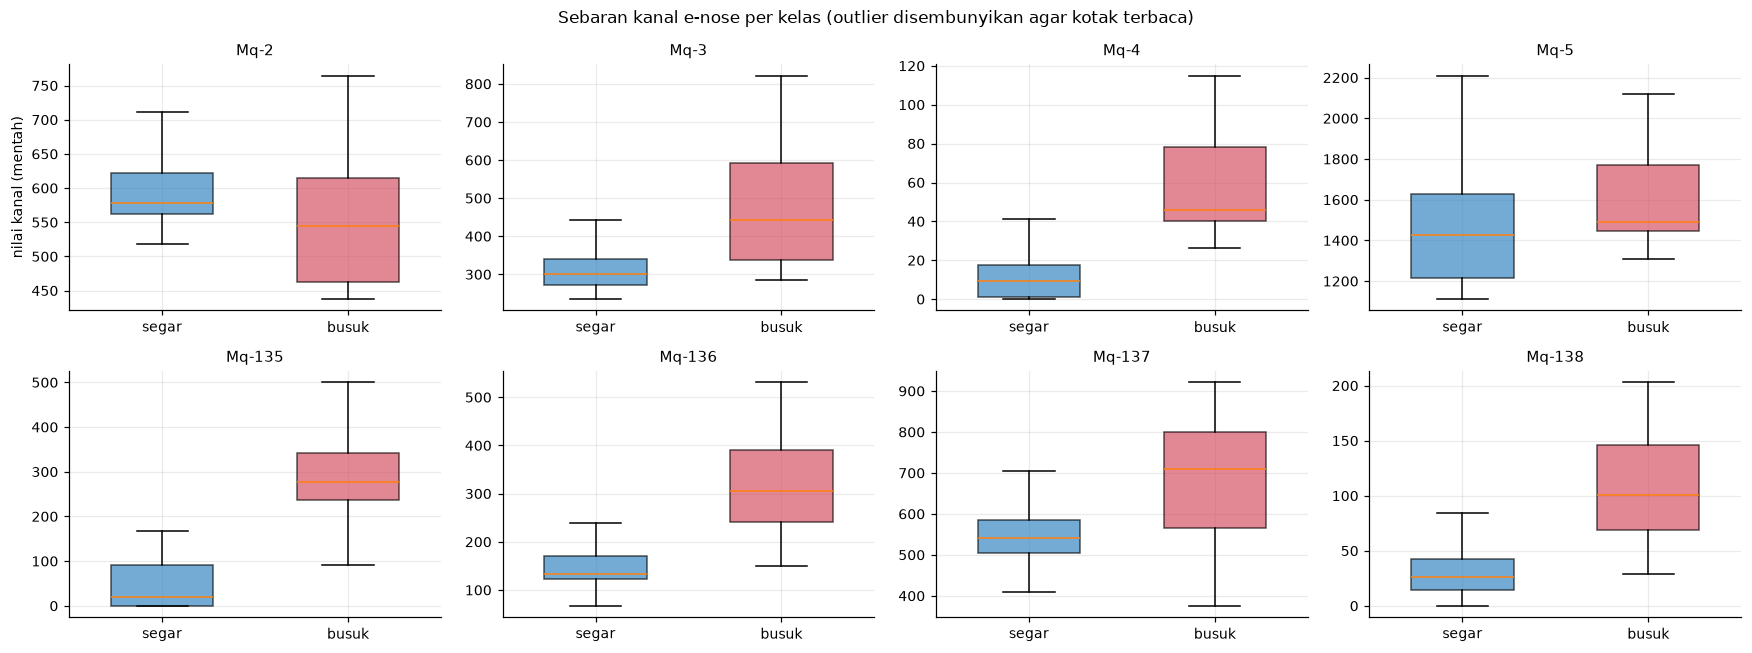

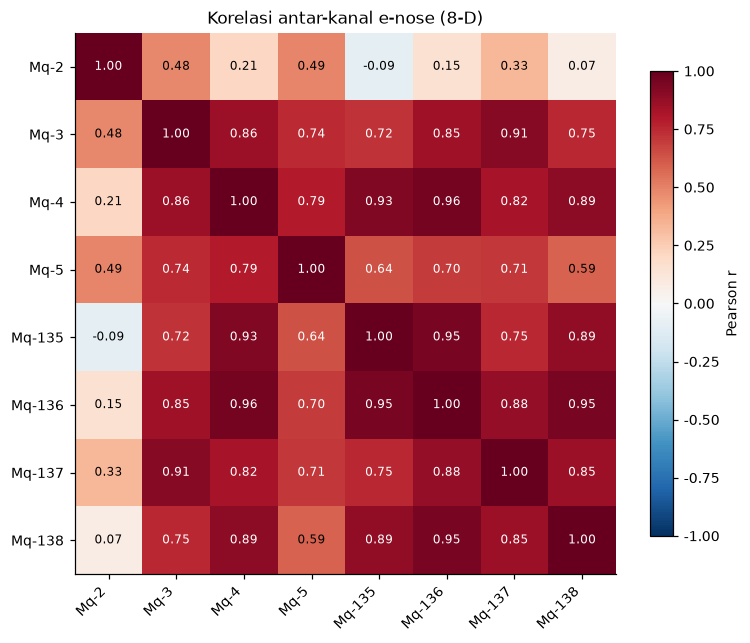

Korelasi |r| > 0.9: [('Mq-3', 'Mq-137', 0.913), ('Mq-4', 'Mq-135', 0.927), ('Mq-4', 'Mq-136', 0.959), ('Mq-135', 'Mq-136', 0.949), ('Mq-136', 'Mq-138', 0.952)]


In [5]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, ch in zip(axes.ravel(), S):
    data = [sen.loc[sen.label == lab, ch].to_numpy() for lab in ["fresh", "spoiled"]]
    bp = ax.boxplot(data, tick_labels=[LABEL_KELAS[l] for l in ["fresh", "spoiled"]],
                    showfliers=False, patch_artist=True, widths=0.55)
    for patch, lab in zip(bp["boxes"], ["fresh", "spoiled"]):
        patch.set_facecolor(KELAS[lab])
        patch.set_alpha(0.65)
    ax.set_title(ch, fontsize=10)
axes[0, 0].set_ylabel("nilai kanal (mentah)")
fig.suptitle("Sebaran kanal e-nose per kelas (outlier disembunyikan agar kotak terbaca)", fontsize=11)
fig.tight_layout()
tampil(fig, "02_sensor_boxplot")

korr = sen[S].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(korr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(S)), S, rotation=45, ha="right")
ax.set_yticks(range(len(S)), S)
for a in range(len(S)):
    for b in range(len(S)):
        v = korr.iloc[a, b]
        ax.text(b, a, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else "black")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Korelasi antar-kanal e-nose (8-D)", fontsize=11)
fig.tight_layout()
tampil(fig, "03_sensor_korelasi")
print("Korelasi |r| > 0.9:",
      [(S[a], S[b], round(float(korr.iloc[a, b]), 3))
       for a in range(len(S)) for b in range(a + 1, len(S)) if abs(korr.iloc[a, b]) > 0.9])

## 3. EDA visual (citra)

**Temuan kunci F1:** 1.896 citra ini bukan 1.896 objek berbeda. Nama berkas
`test_YYYYMMDD_HHMMSSD.jpg` menunjukkan **satu trajektori kamera IP** selama
±64 jam dengan interval 2 menit, dan label berganti **sekali** di satu titik
waktu. Karena itu `group_id` = blok 30 menit, dan dua blok di batas dibuang.

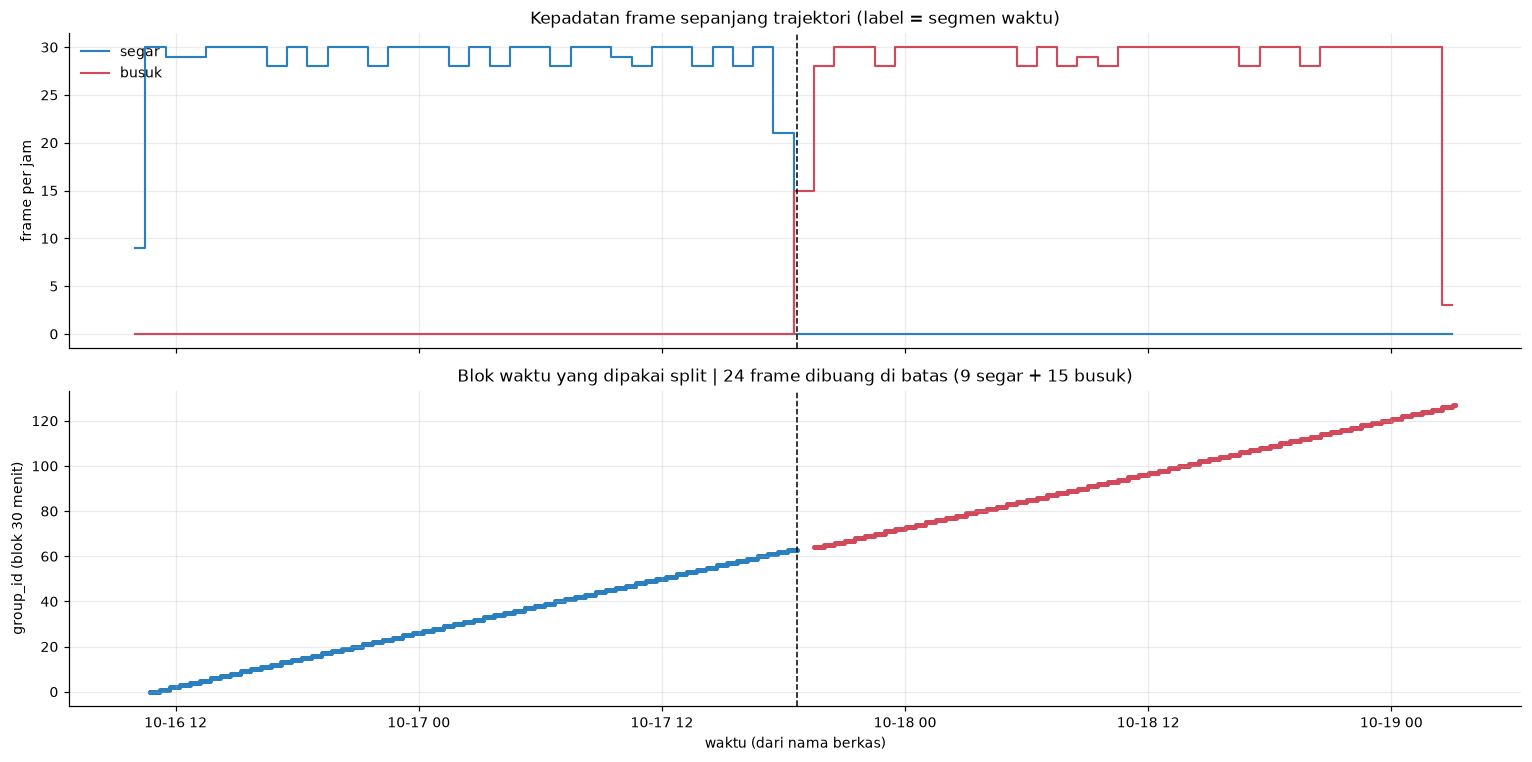

Rentang segar : 2017-10-16 10:43:21 -> 2017-10-17 18:41:21
Rentang busuk : 2017-10-17 19:31:21 -> 2017-10-19 03:09:21
EXIF datetime : {'fresh': '0/10 sampel punya EXIF datetime', 'spoiled': '0/10 sampel punya EXIF datetime'}


In [6]:
vis = vis.assign(timestamp=pd.to_datetime(
    vis["path"].map(lambda p: _visual_timestamp(Path(p).name, cfg["visual"]))
))
assert vis.timestamp.notna().all(), "ada nama berkas yang tidak cocok pola timestamp"

per_jam = (vis.assign(jam=vis.timestamp.dt.floor("h"))
             .groupby(["jam", "label"]).size().unstack(fill_value=0))
batas_visual = vis.loc[vis.label == "fresh", "timestamp"].max()

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for lab in ["fresh", "spoiled"]:
    if lab in per_jam.columns:
        axes[0].plot(per_jam.index, per_jam[lab], drawstyle="steps-mid",
                     color=KELAS[lab], lw=1.4, label=LABEL_KELAS[lab])
axes[0].axvline(batas_visual, color="k", ls="--", lw=1)
axes[0].set_ylabel("frame per jam")
axes[0].legend(loc="upper left", frameon=False)
axes[0].set_title("Kepadatan frame sepanjang trajektori (label = segmen waktu)", fontsize=11)

for lab in ["fresh", "spoiled"]:
    d = vis[vis.label == lab]
    axes[1].scatter(d.timestamp, d.group_id, s=5, color=KELAS[lab], label=LABEL_KELAS[lab])
axes[1].axvline(batas_visual, color="k", ls="--", lw=1)
axes[1].set_ylabel("group_id (blok 30 menit)")
axes[1].set_xlabel("waktu (dari nama berkas)")
b = manifest["visual"]["boundary"]
axes[1].set_title(
    f"Blok waktu yang dipakai split | {b['dibuang']} frame dibuang di batas "
    f"({b['dibuang_per_kelas']['fresh']} segar + {b['dibuang_per_kelas']['spoiled']} busuk)",
    fontsize=11,
)
fig.tight_layout()
tampil(fig, "04_visual_trajektori")

print("Rentang segar :", vis.loc[vis.label == "fresh", "timestamp"].min(), "->", batas_visual)
print("Rentang busuk :", vis.loc[vis.label == "spoiled", "timestamp"].min(), "->",
      vis.loc[vis.label == "spoiled", "timestamp"].max())
print("EXIF datetime :", manifest["visual"]["exif_datetime"])

### 3.1 Contoh citra mentah

Enam frame: awal / tengah / akhir tiap segmen kelas. Perhatikan bahwa perubahan
segar → busuk terjadi **perlahan dan kontinu** — inilah alasan frame bersebelahan
di batas kelas hampir identik tetapi berlabel lawan.

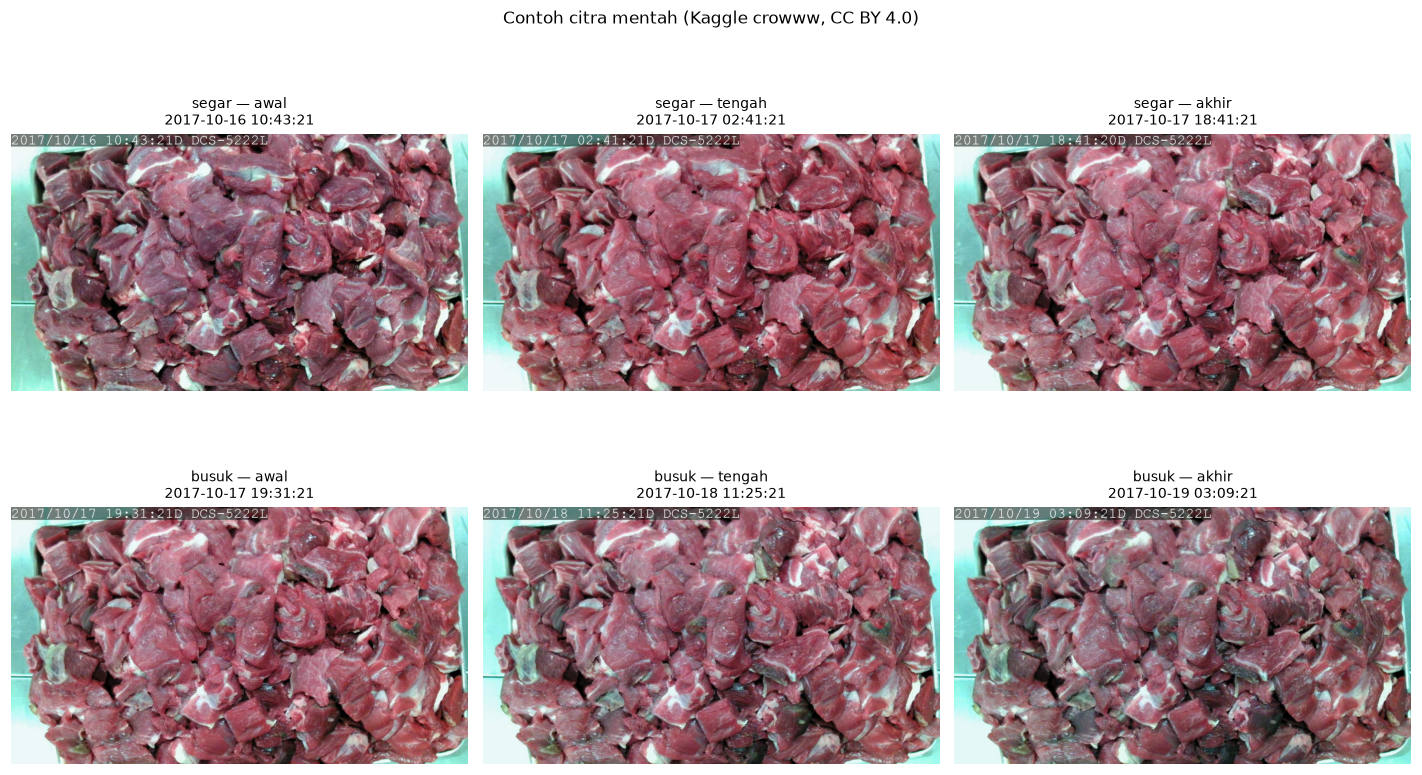

WindowsPath('D:/Documents/S2/Kuliah/261/RFPP/figures/05_visual_contoh_mentah.png')

In [7]:
pilihan = []
for lab in ["fresh", "spoiled"]:
    d = vis[vis.label == lab].sort_values("timestamp")
    for posisi, idx in zip(["awal", "tengah", "akhir"], [0, len(d) // 2, len(d) - 1]):
        pilihan.append((lab, posisi, d.iloc[idx]))

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (lab, posisi, row) in zip(axes.ravel(), pilihan):
    img = Image.open(ROOT / row["path"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"{LABEL_KELAS[lab]} — {posisi}\n{row['timestamp']:%Y-%m-%d %H:%M:%S}", fontsize=9)
    ax.axis("off")
fig.suptitle("Contoh citra mentah (Kaggle crowww, CC BY 4.0)", fontsize=11)
fig.tight_layout()
tampil(fig, "05_visual_contoh_mentah")

### 3.2 Apa yang benar-benar dilihat model

Pra-proses (dari `config.yaml`, dikerjakan di `src/features_visual.py`):
resize 256×256 bicubic → **center crop 80%** (204×204, membuang latar) →
Gaussian σ=1,0 → HSV. Baris kanan adalah masukan nyata ekstraksi fitur.

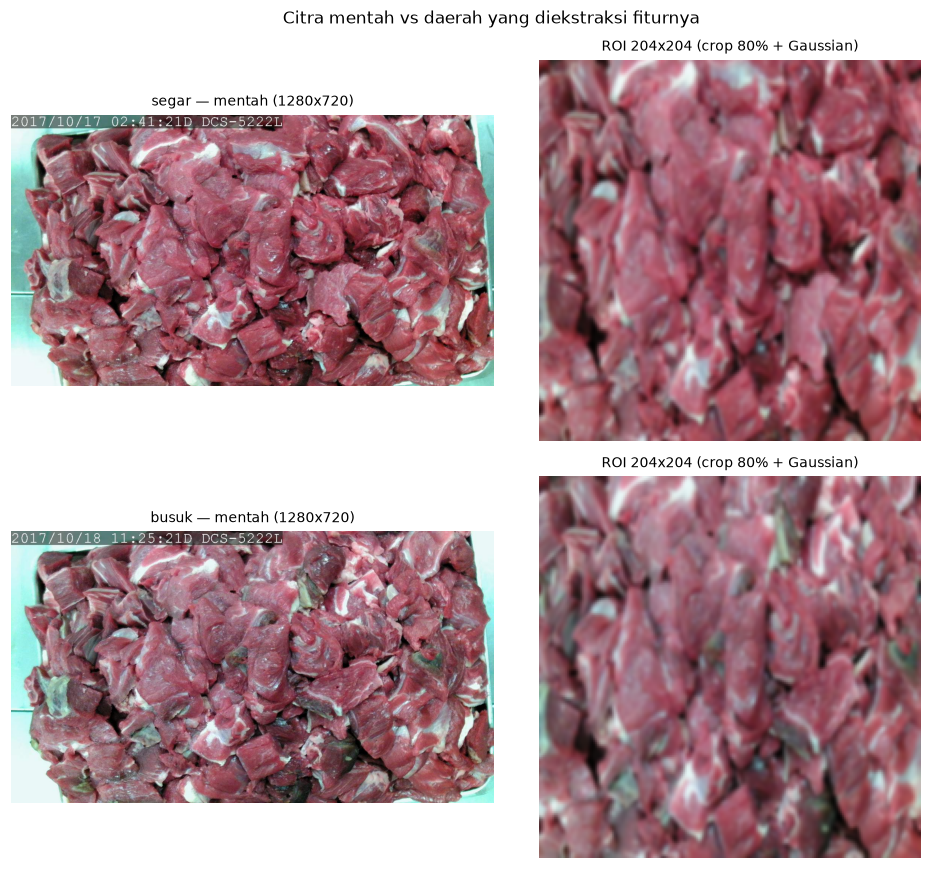

WindowsPath('D:/Documents/S2/Kuliah/261/RFPP/figures/06_visual_roi.png')

In [8]:
contoh = []
for lab in ["fresh", "spoiled"]:
    d = vis[vis.label == lab].sort_values("timestamp")
    contoh.append((lab, d.iloc[len(d) // 2]))

fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for k, (lab, row) in enumerate(contoh):
    img = Image.open(ROOT / row["path"]).convert("RGB")
    axes[k, 0].imshow(img)
    axes[k, 0].set_title(f"{LABEL_KELAS[lab]} — mentah ({img.size[0]}x{img.size[1]})", fontsize=9)
    roi = preprocess(img, cfg["visual"])
    axes[k, 1].imshow(roi)
    axes[k, 1].set_title(f"ROI {roi.shape[1]}x{roi.shape[0]} (crop 80% + Gaussian)", fontsize=9)
    for ax in axes[k]:
        ax.axis("off")
fig.suptitle("Citra mentah vs daerah yang diekstraksi fiturnya", fontsize=11)
fig.tight_layout()
tampil(fig, "06_visual_roi")

### 3.3 Fitur visual sepanjang waktu

Empat fitur wakil: dua bin HSV dan dua properti GLCM. Nama fitur dipetakan dari
`config.yaml` (`f00–f07` = H 8 bin, `f08–f11` = S 4 bin, `f12–f15` = V 4 bin,
`f16–f19` = GLCM contrast/homogeneity/energy/correlation).

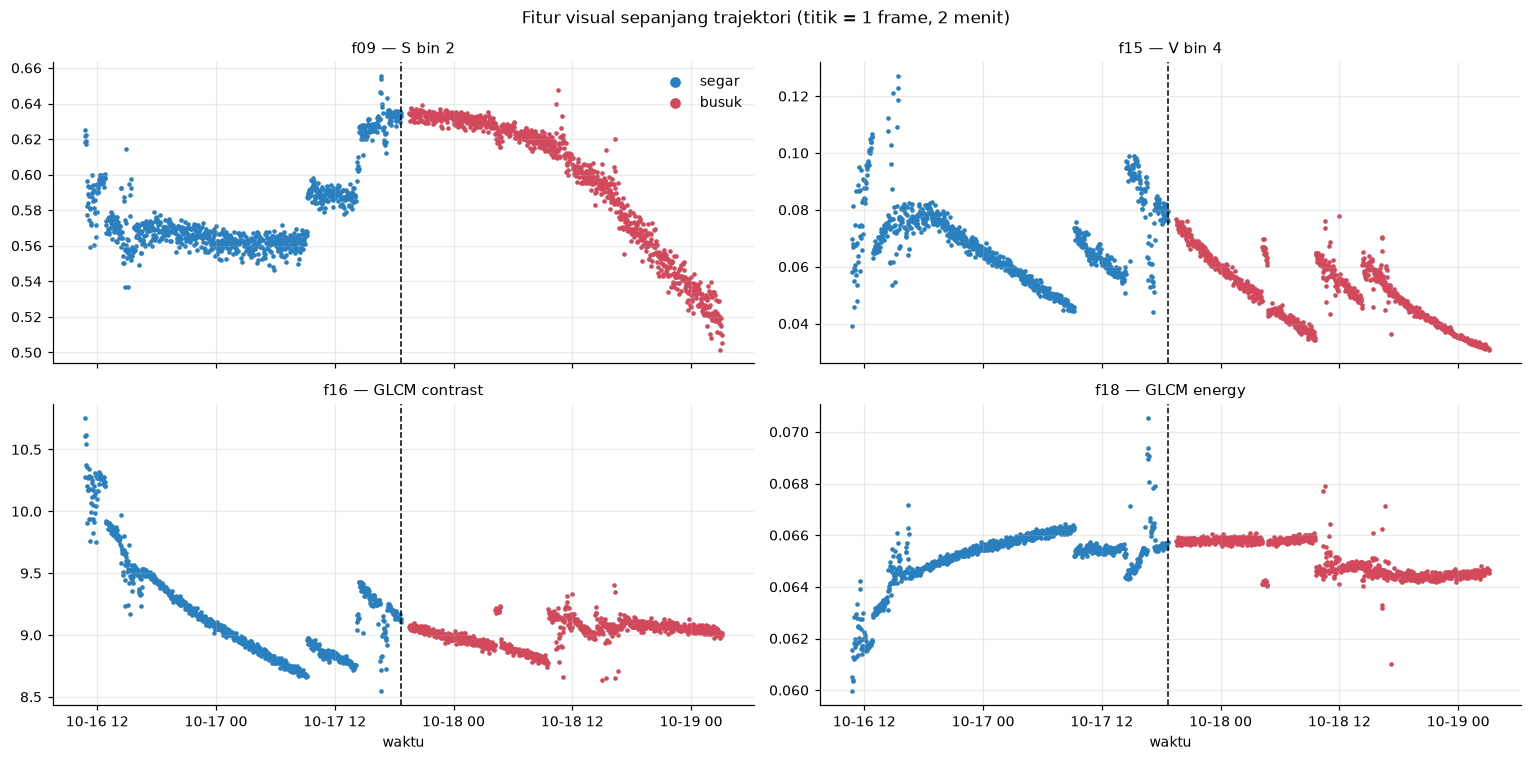

WindowsPath('D:/Documents/S2/Kuliah/261/RFPP/figures/07_visual_fitur_waktu.png')

In [9]:
wakil = ["f09", "f15", "f16", "f18"]
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for ax, f in zip(axes.ravel(), wakil):
    for lab in ["fresh", "spoiled"]:
        d = vis[vis.label == lab]
        ax.scatter(d.timestamp, d[f], s=4, color=KELAS[lab], label=LABEL_KELAS[lab])
    ax.axvline(batas_visual, color="k", ls="--", lw=1)
    ax.set_title(f"{f} — {NAMA_FITUR[f]}", fontsize=10)
axes[0, 0].legend(loc="best", frameon=False, markerscale=3)
for ax in axes[-1]:
    ax.set_xlabel("waktu")
fig.suptitle("Fitur visual sepanjang trajektori (titik = 1 frame, 2 menit)", fontsize=11)
fig.tight_layout()
tampil(fig, "07_visual_fitur_waktu")

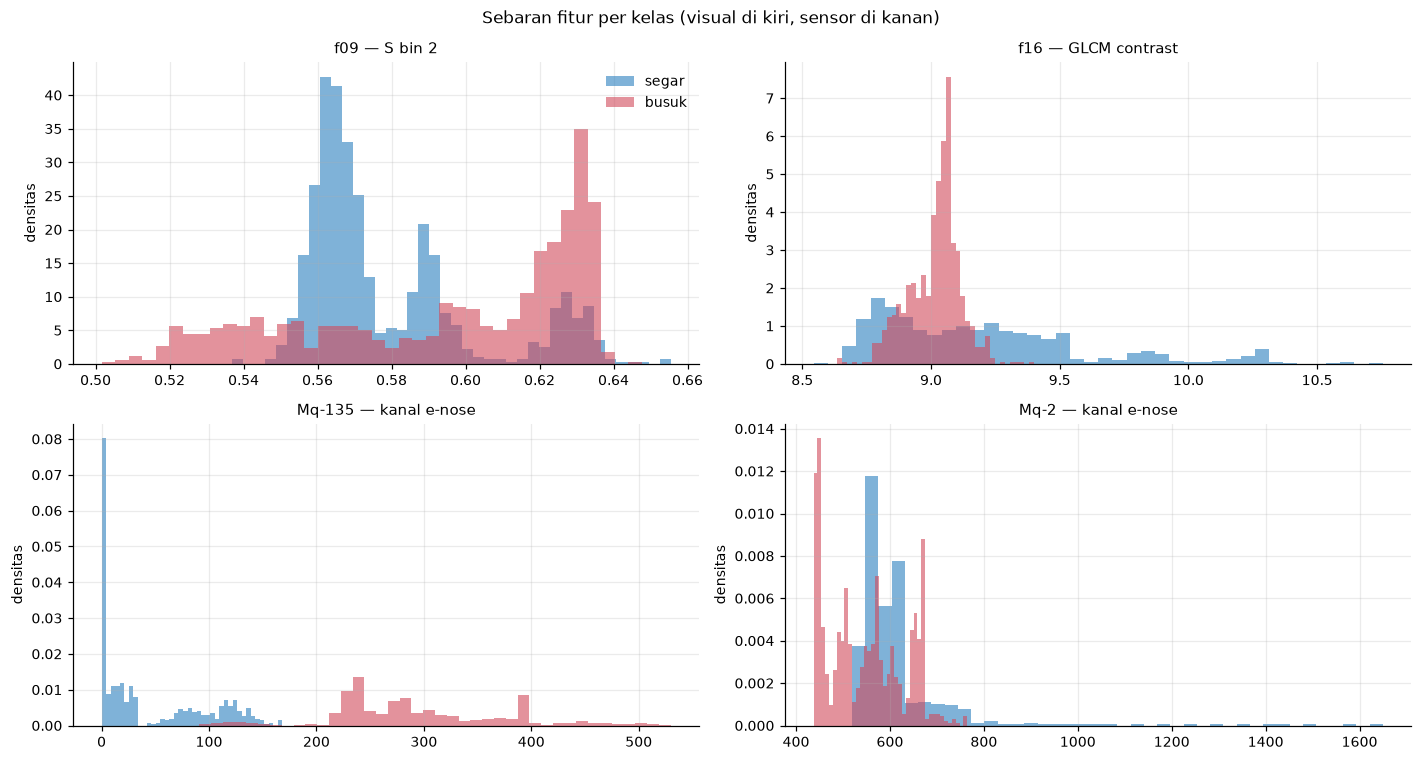

WindowsPath('D:/Documents/S2/Kuliah/261/RFPP/figures/08_histogram_per_kelas.png')

In [10]:
gabungan = [("f09", vis), ("f16", vis), ("Mq-135", sen), ("Mq-2", sen)]
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, (f, df) in zip(axes.ravel(), gabungan):
    for lab in ["fresh", "spoiled"]:
        ax.hist(df.loc[df.label == lab, f], bins=40, density=True, alpha=0.6,
                color=KELAS[lab], label=LABEL_KELAS[lab])
    nama = NAMA_FITUR.get(f, "kanal e-nose")
    ax.set_title(f"{f} — {nama}", fontsize=10)
    ax.set_ylabel("densitas")
axes[0, 0].legend(frameon=False)
fig.suptitle("Sebaran fitur per kelas (visual di kiri, sensor di kanan)", fontsize=11)
fig.tight_layout()
tampil(fig, "08_histogram_per_kelas")

### 3.4 Redundansi di dalam blok visual

Korelasi 20×20 fitur visual. Garis putih membatasi empat grup (H, S, V, GLCM).
Korelasi tinggi **di dalam** blok inilah alasan *per-feature permutation*
meremehkan pentingnya blok: saat satu fitur diacak, fitur lain yang berkorelasi
masih membawa informasi yang sama. Itu sebabnya F5c memakai **block-permutation**
(seluruh 20 kolom diacak bersama dengan urutan baris yang sama).

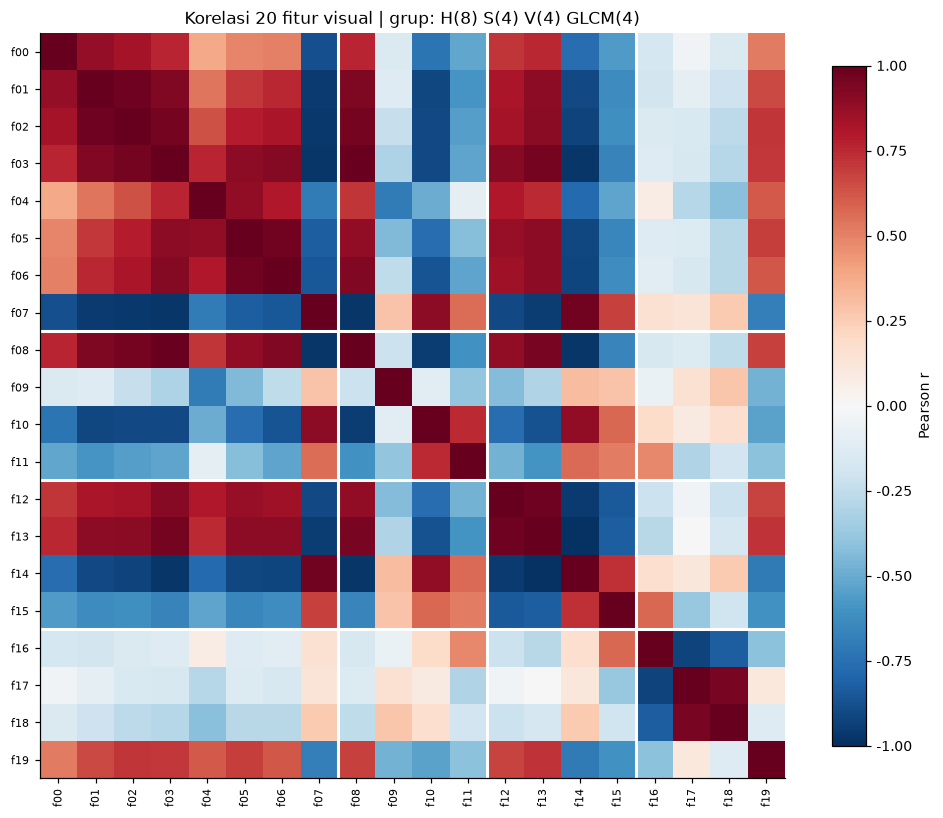

pasangan fitur visual dengan |r| > 0.9: 35 dari 190
[('f01', 'f02', 0.973), ('f01', 'f03', 0.929), ('f01', 'f07', -0.955), ('f01', 'f08', 0.935), ('f01', 'f10', -0.908), ('f01', 'f14', -0.904), ('f02', 'f03', 0.959), ('f02', 'f07', -0.965), ('f02', 'f08', 0.961), ('f02', 'f10', -0.9), ('f02', 'f13', 0.906), ('f02', 'f14', -0.928)]


In [11]:
kv = vis[V].corr()
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(kv, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(V)), V, rotation=90, fontsize=7)
ax.set_yticks(range(len(V)), V, fontsize=7)
for batas in [hb["h"], hb["h"] + hb["s"], hb["h"] + hb["s"] + hb["v"]]:
    ax.axhline(batas - 0.5, color="white", lw=2)
    ax.axvline(batas - 0.5, color="white", lw=2)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Korelasi 20 fitur visual | grup: H(8) S(4) V(4) GLCM(4)", fontsize=11)
fig.tight_layout()
tampil(fig, "09_visual_korelasi")

tinggi = [(V[a], V[b], round(float(kv.iloc[a, b]), 3))
          for a in range(len(V)) for b in range(a + 1, len(V)) if abs(kv.iloc[a, b]) > 0.9]
print(f"pasangan fitur visual dengan |r| > 0.9: {len(tinggi)} dari {len(V) * (len(V) - 1) // 2}")
print(tinggi[:12])

## 4. Protokol pairing: dari mana jumlah baris uji berasal

Urutan wajib anti-bocor: **split tiap modalitas dulu** (blok waktu) → pasangkan
1-ke-1 **di dalam** latih dan **di dalam** uji, acak tanpa pengembalian, per kelas
→ fit clip/scaler **hanya di latih** → fit model **hanya di latih**. Baseline
unimodal memakai baris berpasangan yang **sama persis** dengan fused, jadi
perbandingannya berpasangan, bukan kebetulan.

Kardinalitas pasangan per kelas = `min(jumlah visual, jumlah sensor)` kelas itu.
Ini langit-langit struktural, bukan pilihan.

,visual,sensor,pasangan_maks,sisa_visual_tak_terpasang,sisa_sensor_tak_terpasang
label,,,,,
segar,939,625,625,314,0
busuk,933,1110,933,0,177


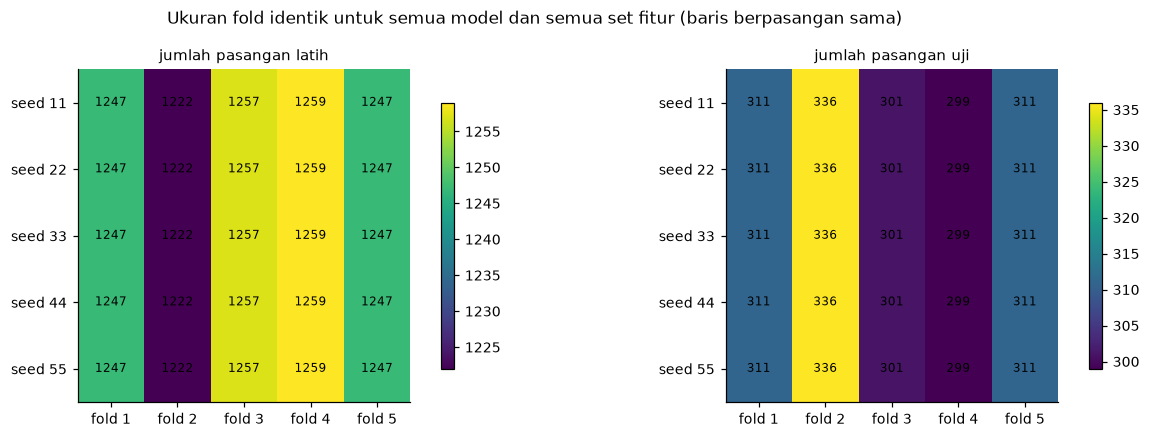

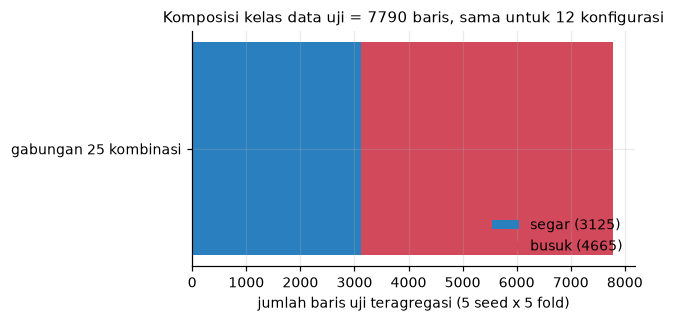

Unit replikasi = seed pairing (5 seed). Rata-rata dihitung per seed dulu (5 fold), baru mean±sd antar seed (ddof=1).


In [12]:
kart = pd.DataFrame({
    "visual": vis.groupby("label").size(),
    "sensor": sen.groupby("label").size(),
}).rename(index=LABEL_KELAS)
kart["pasangan_maks"] = kart.min(axis=1)
kart["sisa_visual_tak_terpasang"] = kart.visual - kart.pasangan_maks
kart["sisa_sensor_tak_terpasang"] = kart.sensor - kart.pasangan_maks
display(kart)

fused_std = metrics[(metrics.feature_set == "fused") & (metrics.scaling == "standard")]
nt = fused_std.drop_duplicates(["seed", "fold"]).pivot(index="seed", columns="fold", values="n_test")
ntr = fused_std.drop_duplicates(["seed", "fold"]).pivot(index="seed", columns="fold", values="n_train")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, tab, judul in [(axes[0], ntr, "jumlah pasangan latih"), (axes[1], nt, "jumlah pasangan uji")]:
    im = ax.imshow(tab.to_numpy(), cmap="viridis")
    ax.set_xticks(range(tab.shape[1]), [f"fold {c}" for c in tab.columns])
    ax.set_yticks(range(tab.shape[0]), [f"seed {r}" for r in tab.index])
    for a in range(tab.shape[0]):
        for b in range(tab.shape[1]):
            ax.text(b, a, str(int(tab.iloc[a, b])), ha="center", va="center", fontsize=8,
                    color="white" if tab.iloc[a, b] < tab.to_numpy().max() * 0.6 else "black")
    ax.grid(False)
    ax.set_title(judul, fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle("Ukuran fold identik untuk semua model dan semua set fitur (baris berpasangan sama)",
             fontsize=11)
fig.tight_layout()
tampil(fig, "10_ukuran_fold")

komp = conf_core.assign(segar=lambda d: d.tn + d.fp, busuk=lambda d: d.fn + d.tp)
assert komp.segar.nunique() == 1 and komp.busuk.nunique() == 1, "komposisi uji berbeda antar konfigurasi"
total = int(komp.segar.iloc[0] + komp.busuk.iloc[0])
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(["gabungan 25 kombinasi"], [komp.segar.iloc[0]], color=KELAS["fresh"],
        label=f"segar ({komp.segar.iloc[0]})")
ax.barh(["gabungan 25 kombinasi"], [komp.busuk.iloc[0]], left=[komp.segar.iloc[0]],
        color=KELAS["spoiled"], label=f"busuk ({komp.busuk.iloc[0]})")
ax.set_xlabel("jumlah baris uji teragregasi (5 seed x 5 fold)")
ax.legend(frameon=False, loc="lower right")
ax.set_title(f"Komposisi kelas data uji = {total} baris, sama untuk 12 konfigurasi", fontsize=10)
fig.tight_layout()
tampil(fig, "11_composisi_uji")
print(f"Unit replikasi = seed pairing ({len(cfg['protocol']['pairing_seeds'])} seed). "
      f"Rata-rata dihitung per seed dulu (5 fold), baru mean±sd antar seed (ddof=1).")

## 5. Evaluasi komparatif (F5)

3 set fitur × 4 model × 5 seed × 5 fold = **300 fit inti**, ditambah 50 fit
varian scaling (fused × model berbasis jarak) = 350 baris di `metrics.csv`.
Metrik utama: **macro-F1** (kelas tidak seimbang sempurna setelah pairing).

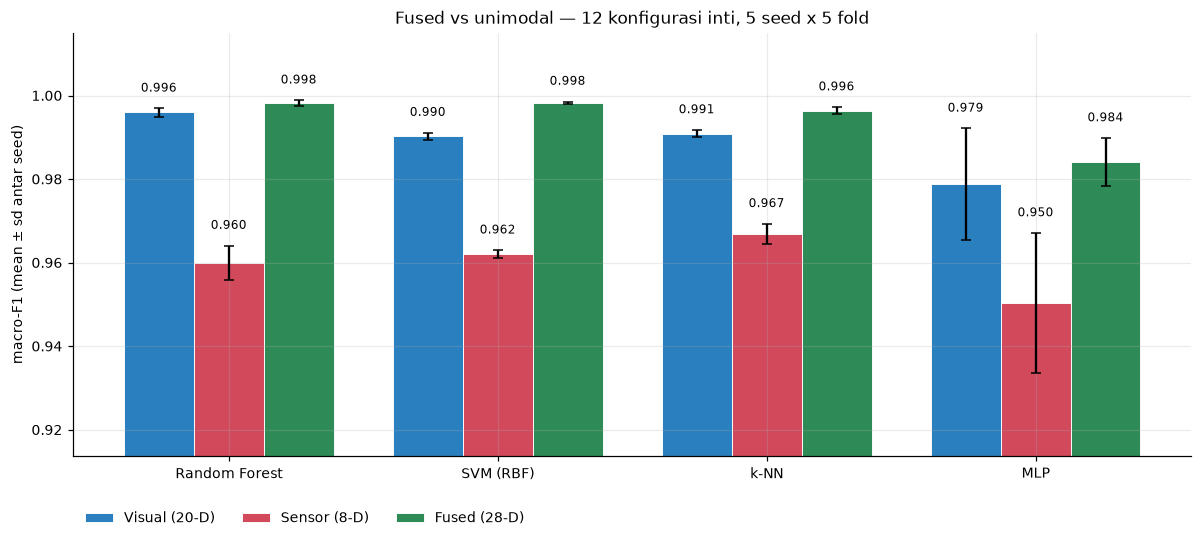

,Visual (20-D),Sensor (8-D),Fused (28-D)
Random Forest,0.9959,0.9600,0.9981
SVM (RBF),0.9902,0.9621,0.9983
k-NN,0.9909,0.9668,0.9964
MLP,0.9788,0.9503,0.9841


In [13]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(MODEL))
w = 0.26
for k, fs in enumerate(SET):
    d = core[core.feature_set == fs].set_index("model").loc[MODEL]
    posisi = x + (k - 1) * w
    ax.bar(posisi, d.macro_f1_mean, w, yerr=d.macro_f1_std, capsize=3,
           color=WARNA[fs], label=LABEL_SET[fs], edgecolor="white", linewidth=0.6)
    for xi, v, s in zip(posisi, d.macro_f1_mean, d.macro_f1_std):
        ax.text(xi, v + s + 0.004, f"{v:.3f}", ha="center", fontsize=8)
bawah = float((core.macro_f1_mean - core.macro_f1_std).min())
ax.set_ylim(bawah - 0.02, 1.015)
ax.set_xticks(x, [LABEL_MODEL[m] for m in MODEL])
ax.set_ylabel("macro-F1 (mean ± sd antar seed)")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.10), ncol=3)
ax.set_title("Fused vs unimodal — 12 konfigurasi inti, 5 seed x 5 fold", fontsize=11)
fig.tight_layout()
tampil(fig, "12_macro_f1_per_set")

tabel = core.pivot_table(index="model", columns="feature_set", values="macro_f1_mean").loc[MODEL, SET]
tabel.columns = [LABEL_SET[c] for c in tabel.columns]
tabel.index = [LABEL_MODEL[m] for m in tabel.index]
display(tabel.round(4))

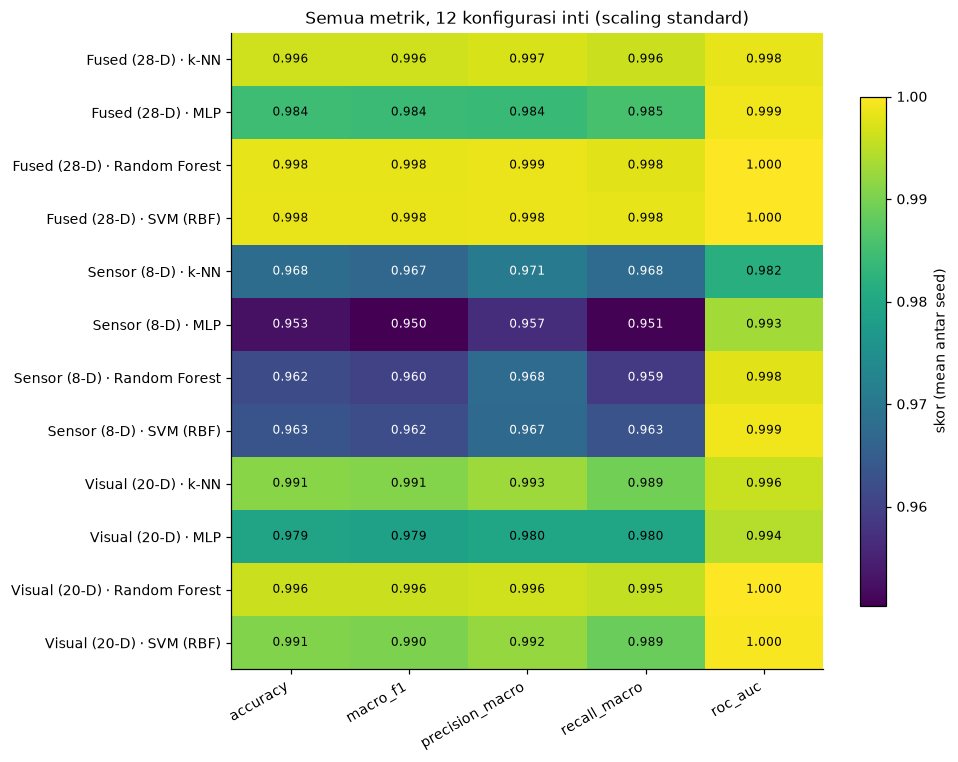

WindowsPath('D:/Documents/S2/Kuliah/261/RFPP/figures/13_heatmap_metrik.png')

In [14]:
METRIK = cfg["metrics"]["report"]
nama_baris = [f"{LABEL_SET[r.feature_set]} · {LABEL_MODEL[r.model]}" for r in core.itertuples()]
nilai = core[[f"{m}_mean" for m in METRIK]].to_numpy()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(nilai, cmap="viridis", vmin=float(nilai.min()), vmax=1.0, aspect="auto")
ax.set_xticks(range(len(METRIK)), METRIK, rotation=30, ha="right")
ax.set_yticks(range(len(nama_baris)), nama_baris)
for a in range(nilai.shape[0]):
    for b in range(nilai.shape[1]):
        ax.text(b, a, f"{nilai[a, b]:.3f}", ha="center", va="center", fontsize=8,
                color="white" if nilai[a, b] < (nilai.min() + 1.0) / 2 else "black")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="skor (mean antar seed)")
ax.set_title("Semua metrik, 12 konfigurasi inti (scaling standard)", fontsize=11)
fig.tight_layout()
tampil(fig, "13_heatmap_metrik")

### 5.1 Selisih berpasangan per seed

Karena baris uji identik, selisihnya bisa dihitung **per seed** lalu diuji arahnya:

* `delta_vs_visual` = fused − visual → **kontribusi blok sensor**
* `delta_vs_sensor` = fused − sensor → **kontribusi blok visual**

Uji tanda satu sisi (`binomtest`, H₀: peluang positif = ½) menjawab "apakah
unggulnya konsisten", bukan "seberapa besar". Dengan hanya 5 seed, uji ini
**lemah**: 5/5 positif memberi p = 0,031, dan satu seed negatif saja sudah
membuat p = 0,188. Jangan menulis "signifikan" tanpa menyebut n = 5.

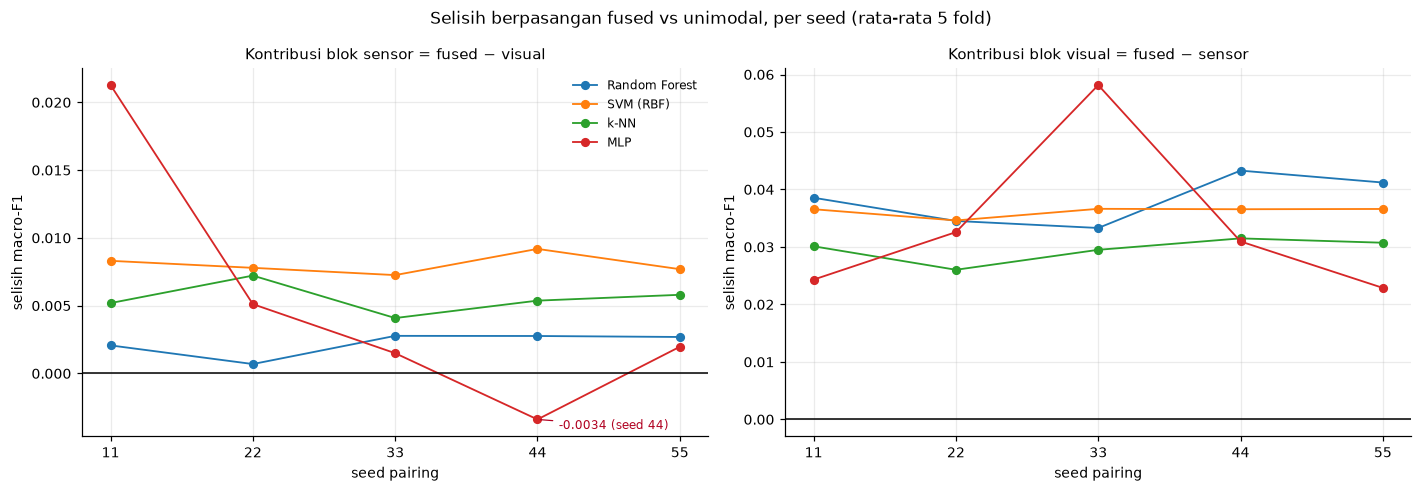

,model,kontribusi_blok,positif,mean,min,max,p_uji_tanda
0,Random Forest,sensor,5/5,0.0022,0.0007,0.0028,0.0312
1,Random Forest,visual,5/5,0.0382,0.0333,0.0433,0.0312
2,SVM (RBF),sensor,5/5,0.0080,0.0073,0.0092,0.0312
3,SVM (RBF),visual,5/5,0.0362,0.0346,0.0366,0.0312
4,k-NN,sensor,5/5,0.0055,0.0041,0.0072,0.0312
5,k-NN,visual,5/5,0.0296,0.0260,0.0315,0.0312
6,MLP,sensor,4/5,0.0053,-0.0034,0.0213,0.1875
7,MLP,visual,5/5,0.0338,0.0229,0.0582,0.0312


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
panel = [
    ("delta_vs_visual", "Kontribusi blok sensor = fused − visual", axes[0]),
    ("delta_vs_sensor", "Kontribusi blok visual = fused − sensor", axes[1]),
]
seeds = sorted(delta.seed.unique())
for kolom, judul, ax in panel:
    for m in MODEL:
        d = delta[delta.model == m].sort_values("seed")
        ax.plot(d.seed, d[kolom], marker="o", ms=5, lw=1.2, label=LABEL_MODEL[m])
        for r in d.itertuples():
            if getattr(r, kolom) <= 0:
                ax.annotate(f"{getattr(r, kolom):+.4f} (seed {r.seed})",
                            (r.seed, getattr(r, kolom)), textcoords="offset points",
                            xytext=(14, -4), ha="left", va="center", fontsize=8, color="#b00020",
                            arrowprops=dict(arrowstyle="-", color="#b00020", lw=0.8))
    ax.axhline(0, color="k", lw=1)
    ax.set_xticks(seeds, [str(s) for s in seeds])
    ax.set_xlabel("seed pairing")
    ax.set_ylabel("selisih macro-F1")
    ax.set_title(judul, fontsize=10)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Selisih berpasangan fused vs unimodal, per seed (rata-rata 5 fold)", fontsize=11)
fig.tight_layout()
tampil(fig, "14_selisih_berpasangan")

uji = []
for m in MODEL:
    d = delta[delta.model == m]
    for kolom, blok in [("delta_vs_visual", "sensor"), ("delta_vs_sensor", "visual")]:
        k = int((d[kolom] > 0).sum())
        n = len(d)
        uji.append({
            "model": LABEL_MODEL[m],
            "kontribusi_blok": blok,
            "positif": f"{k}/{n}",
            "mean": round(float(d[kolom].mean()), 4),
            "min": round(float(d[kolom].min()), 4),
            "max": round(float(d[kolom].max()), 4),
            "p_uji_tanda": round(float(binomtest(k, n, 0.5, alternative="greater").pvalue), 4),
        })
display(pd.DataFrame(uji))

### 5.2 Efek penskalaan pada model berbasis jarak

`config.yaml` menetapkan penskalaan **setelah** concatenation untuk seluruh
vektor 28-D (bukan hanya cabang sensor). Varian `none` dijalankan hanya untuk
fused × k-NN dan SVM, karena keduanya memakai jarak euclidean; RF dan MLP
tidak punya varian ini di grid.

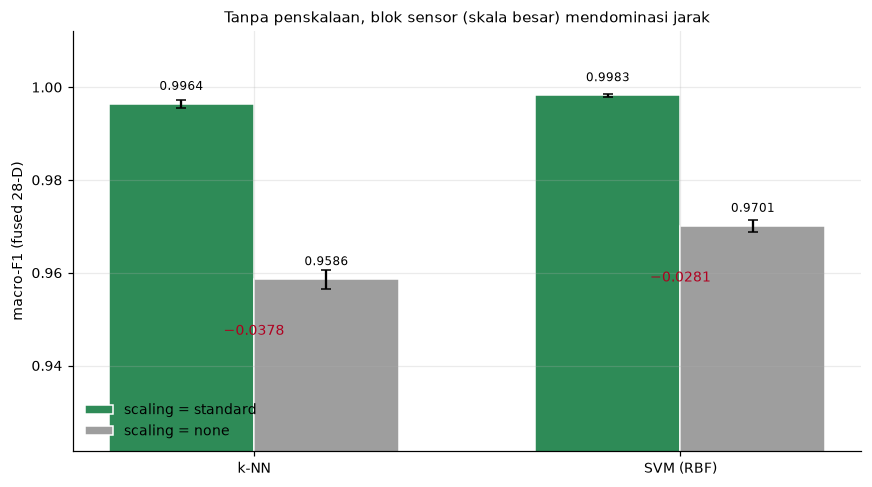

,model,scaling,macro_f1_mean,macro_f1_std,accuracy_mean
0,knn,none,0.9586,0.0020,0.9606
1,knn,standard,0.9964,0.0008,0.9965
4,svm_rbf,none,0.9701,0.0013,0.9704
5,svm_rbf,standard,0.9983,0.0003,0.9983


In [16]:
dist = cfg["fusion"]["distance_models"]
var = summary[(summary.feature_set == "fused") & (summary.model.isin(dist))]
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(dist))
w = 0.34
for k, sc in enumerate(["standard", "none"]):
    d = var[var.scaling == sc].set_index("model").loc[dist]
    posisi = x + (k - 0.5) * w
    ax.bar(posisi, d.macro_f1_mean, w, yerr=d.macro_f1_std, capsize=3,
           color="#2e8b57" if sc == "standard" else "#9e9e9e",
           label=f"scaling = {sc}", edgecolor="white")
    for xi, v in zip(posisi, d.macro_f1_mean):
        ax.text(xi, v + 0.003, f"{v:.4f}", ha="center", fontsize=8)
for k, m in enumerate(dist):
    a = float(var[(var.model == m) & (var.scaling == "standard")].macro_f1_mean.iloc[0])
    b = float(var[(var.model == m) & (var.scaling == "none")].macro_f1_mean.iloc[0])
    ax.annotate(f"−{a - b:.4f}", (k, min(a, b) - 0.012), ha="center", fontsize=9, color="#b00020")
bawah = float((var.macro_f1_mean - var.macro_f1_std).min())
ax.set_ylim(bawah - 0.035, 1.012)
ax.set_xticks(x, [LABEL_MODEL[m] for m in dist])
ax.set_ylabel("macro-F1 (fused 28-D)")
ax.legend(frameon=False, loc="lower left")
ax.set_title("Tanpa penskalaan, blok sensor (skala besar) mendominasi jarak", fontsize=10)
fig.tight_layout()
tampil(fig, "15_efek_scaling")
display(var[["model", "scaling", "macro_f1_mean", "macro_f1_std", "accuracy_mean"]].round(4))

### 5.3 Confusion matrix teragregasi

Positif = **busuk** (`config.metrics.positive_label`). Angka di bawah adalah
gabungan 5 seed × 5 fold, jadi totalnya ribuan, bukan satu fold.

* **FP** = daging segar ditolak sebagai busuk → kerugian ekonomi (alarm palsu).
* **FN** = daging busuk lolos sebagai segar → **risiko keamanan pangan**.

`FN = 0` pada beberapa konfigurasi **bukan** bukti model tidak pernah melewatkan
pembusukan; itu konsekuensi kelas busuk yang mudah dipisahkan oleh warna/waktu
di dataset ini (lihat batas klaim di bagian 8).

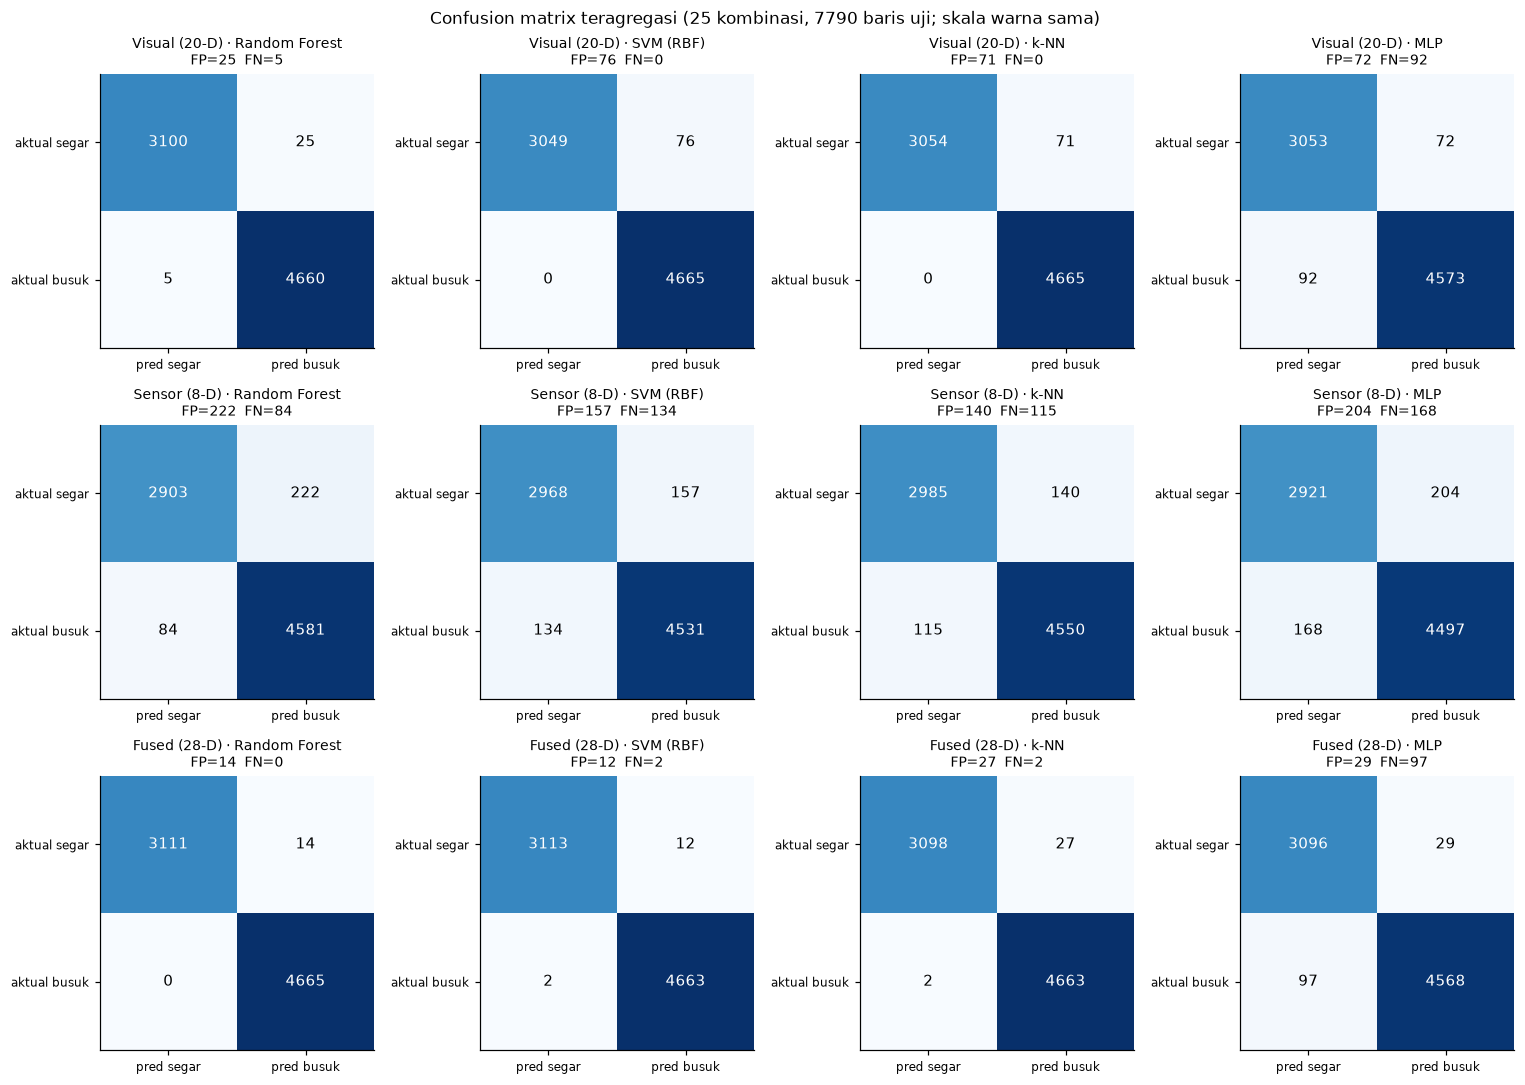

,feature_set,model,tn,fp,fn,tp,alarm_palsu_per_1000_segar,busuk_lolos_per_1000_busuk
0,fused,knn,3098,27,2,4663,8.6,0.4
1,fused,mlp,3096,29,97,4568,9.3,20.8
2,fused,random_forest,3111,14,0,4665,4.5,0.0
3,fused,svm_rbf,3113,12,2,4663,3.8,0.4
4,sensor,knn,2985,140,115,4550,44.8,24.7
5,sensor,mlp,2921,204,168,4497,65.3,36.0
6,sensor,random_forest,2903,222,84,4581,71.0,18.0
7,sensor,svm_rbf,2968,157,134,4531,50.2,28.7
8,visual,knn,3054,71,0,4665,22.7,0.0
9,visual,mlp,3053,72,92,4573,23.0,19.7


In [17]:
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
vmax = float(conf_core[["tn", "fp", "fn", "tp"]].to_numpy().max())
for ax, fs in zip(axes, SET):
    for bx, m in zip(ax, MODEL):
        r = conf_core[(conf_core.feature_set == fs) & (conf_core.model == m)].iloc[0]
        cm = np.array([[r.tn, r.fp], [r.fn, r.tp]])
        bx.imshow(cm, cmap="Blues", vmin=0, vmax=vmax)
        bx.set_xticks([0, 1], ["pred segar", "pred busuk"], fontsize=8)
        bx.set_yticks([0, 1], ["aktual segar", "aktual busuk"], fontsize=8)
        for a in range(2):
            for b in range(2):
                bx.text(b, a, f"{int(cm[a, b])}", ha="center", va="center", fontsize=10,
                        color="white" if cm[a, b] > vmax * 0.55 else "black")
        bx.grid(False)
        bx.set_title(f"{LABEL_SET[fs]} · {LABEL_MODEL[m]}\nFP={int(r.fp)}  FN={int(r.fn)}",
                     fontsize=9)
fig.suptitle(f"Confusion matrix teragregasi (25 kombinasi, {total} baris uji; skala warna sama)",
             fontsize=11)
fig.tight_layout()
tampil(fig, "16_confusion_matrix")

laju = conf_core.copy()
laju["fp_rate"] = laju.fp / (laju.tn + laju.fp)
laju["fn_rate"] = laju.fn / (laju.fn + laju.tp)
laju["alarm_palsu_per_1000_segar"] = (laju.fp_rate * 1000).round(1)
laju["busuk_lolos_per_1000_busuk"] = (laju.fn_rate * 1000).round(1)
display(laju[["feature_set", "model", "tn", "fp", "fn", "tp",
              "alarm_palsu_per_1000_segar", "busuk_lolos_per_1000_busuk"]]
        .sort_values(["feature_set", "model"]).reset_index(drop=True))

## 6. Probe pasangan diskordan (F5b)

Pasangan **hanya-uji** yang sengaja dibuat bertentangan: visual segar ↔ sensor
busuk, dan visual busuk ↔ sensor segar. **Tidak ada ground truth**, jadi
**akurasi dilarang dihitung** (`config.probe.accuracy_claim = forbidden`).
Yang diukur hanya: dengan label siapa model setuju, dan berapa proporsi
pasangan yang ditolak sebagai busuk.

Ini menguji **perilaku saat modalitas bertentangan**, bukan kemampuan deteksi.

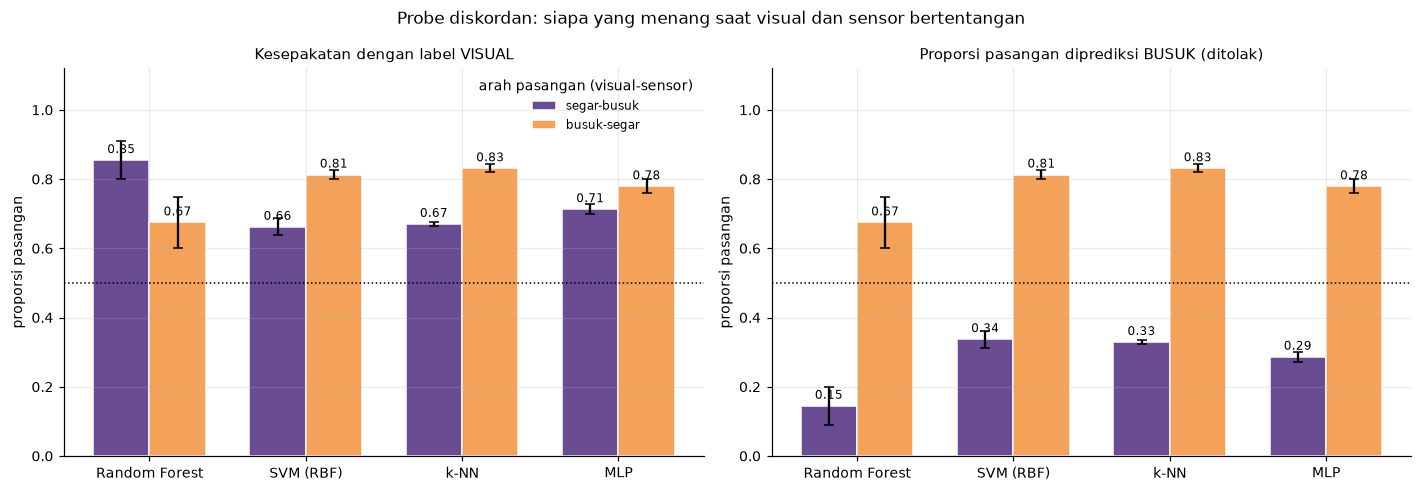

,direction,model,n_pairs,agreement_visual_mean,agreement_sensor_mean,share_predicted_busuk_mean
0,busuk-segar,knn,3125,0.8314,0.1686,0.8314
1,busuk-segar,mlp,3125,0.7793,0.2207,0.7793
2,busuk-segar,random_forest,3125,0.6750,0.3250,0.6750
3,busuk-segar,svm_rbf,3125,0.8131,0.1869,0.8131
4,segar-busuk,knn,4695,0.6706,0.3294,0.3294
5,segar-busuk,mlp,4695,0.7132,0.2868,0.2868
6,segar-busuk,random_forest,4695,0.8550,0.1450,0.1450
7,segar-busuk,svm_rbf,4695,0.6622,0.3378,0.3378


Total pasangan diskordan uji: 31280 baris tercatat (200 kombinasi seed x fold x arah x model).
Pasangan latih terpakai: 0 (dijaga di src/probe_discordant.py dan tests/test_probe_discordant.py).


In [18]:
arah = ["segar-busuk", "busuk-segar"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(MODEL))
w = 0.36
for ax, kolom, judul in [
    (axes[0], "agreement_visual", "Kesepakatan dengan label VISUAL"),
    (axes[1], "share_predicted_busuk", "Proporsi pasangan diprediksi BUSUK (ditolak)"),
]:
    for k, a in enumerate(arah):
        d = probe_sum[probe_sum.direction == a].set_index("model").loc[MODEL]
        posisi = x + (k - 0.5) * w
        ax.bar(posisi, d[f"{kolom}_mean"], w, yerr=d[f"{kolom}_std"], capsize=3,
               color=ARAH[a], label=a, edgecolor="white")
        for xi, v in zip(posisi, d[f"{kolom}_mean"]):
            ax.text(xi, v + 0.02, f"{v:.2f}", ha="center", fontsize=8)
    ax.axhline(0.5, color="k", ls=":", lw=1)
    ax.set_ylim(0, 1.12)
    ax.set_xticks(x, [LABEL_MODEL[m] for m in MODEL])
    ax.set_title(judul, fontsize=10)
    ax.set_ylabel("proporsi pasangan")
axes[0].legend(frameon=False, title="arah pasangan (visual-sensor)", fontsize=8)
fig.suptitle("Probe diskordan: siapa yang menang saat visual dan sensor bertentangan", fontsize=11)
fig.tight_layout()
tampil(fig, "17_probe_diskordan")

display(probe_sum[["direction", "model", "n_pairs", "agreement_visual_mean",
                   "agreement_sensor_mean", "share_predicted_busuk_mean"]].round(4))
print(f"Total pasangan diskordan uji: {int(probe.n_pairs.sum())} baris tercatat "
      f"({len(probe)} kombinasi seed x fold x arah x model).")
print("Pasangan latih terpakai: 0 (dijaga di src/probe_discordant.py dan tests/test_probe_discordant.py).")

### 6.1 Kepercayaan model — **tidak boleh dibandingkan antar model**

k-NN, RF, dan MLP memakai `max(predict_proba)` (0–1), sedangkan SVM memakai
`|decision_function|` (margin, tak terbatas dan berskala beda). Angka di kolom
`confidence` karena itu **hanya boleh dibaca dalam model yang sama**, antar arah.

,direction,model,confidence_kind,confidence_mean,confidence_std
0,busuk-segar,MLP,max_proba,0.8112,0.0086
1,segar-busuk,MLP,max_proba,0.8074,0.0072
2,busuk-segar,Random Forest,max_proba,0.6780,0.0054
3,segar-busuk,Random Forest,max_proba,0.6418,0.0133
4,busuk-segar,SVM (RBF),abs_margin,0.6658,0.0130
5,segar-busuk,SVM (RBF),abs_margin,0.4287,0.0134
6,busuk-segar,k-NN,max_proba,0.9695,0.0037
7,segar-busuk,k-NN,max_proba,0.9627,0.0033


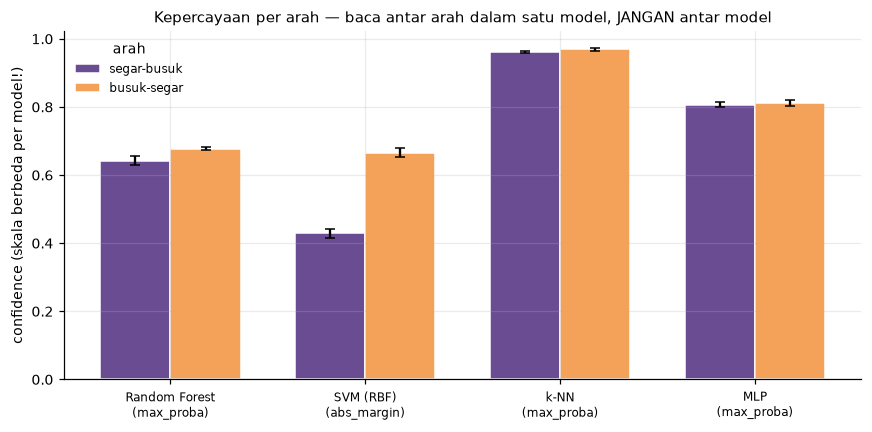

WindowsPath('D:/Documents/S2/Kuliah/261/RFPP/figures/18_probe_confidence.png')

In [19]:
kind = probe.drop_duplicates("model")[["model", "confidence_kind"]]
kepercayaan = probe_sum.merge(kind, on="model")
kepercayaan["model"] = kepercayaan.model.map(LABEL_MODEL)
display(kepercayaan[["direction", "model", "confidence_kind", "confidence_mean", "confidence_std"]]
        .sort_values(["model", "direction"]).reset_index(drop=True).round(4))

fig, ax = plt.subplots(figsize=(8, 4))
for k, a in enumerate(arah):
    d = probe_sum[probe_sum.direction == a].set_index("model").loc[MODEL]
    posisi = x + (k - 0.5) * w
    ax.bar(posisi, d.confidence_mean, w, yerr=d.confidence_std, capsize=3,
           color=ARAH[a], label=a, edgecolor="white")
ax.set_xticks(x, [f"{LABEL_MODEL[m]}\n({kind.set_index('model').loc[m, 'confidence_kind']})"
                  for m in MODEL], fontsize=8)
ax.set_ylabel("confidence (skala berbeda per model!)")
ax.legend(frameon=False, title="arah", fontsize=8)
ax.set_title("Kepercayaan per arah — baca antar arah dalam satu model, JANGAN antar model", fontsize=10)
fig.tight_layout()
tampil(fig, "18_probe_confidence")

## 7. Dominasi modalitas (F5c)

**Block-permutation importance** pada data uji: seluruh 20 kolom visual diacak
**bersama-sama dengan urutan baris yang sama** (korelasi di dalam blok tetap
utuh), lalu seluruh 8 kolom sensor. Yang diukur = penurunan macro-F1 dari
baseline, diulang 20 kali per target per fold. Model **tidak** dilatih ulang.

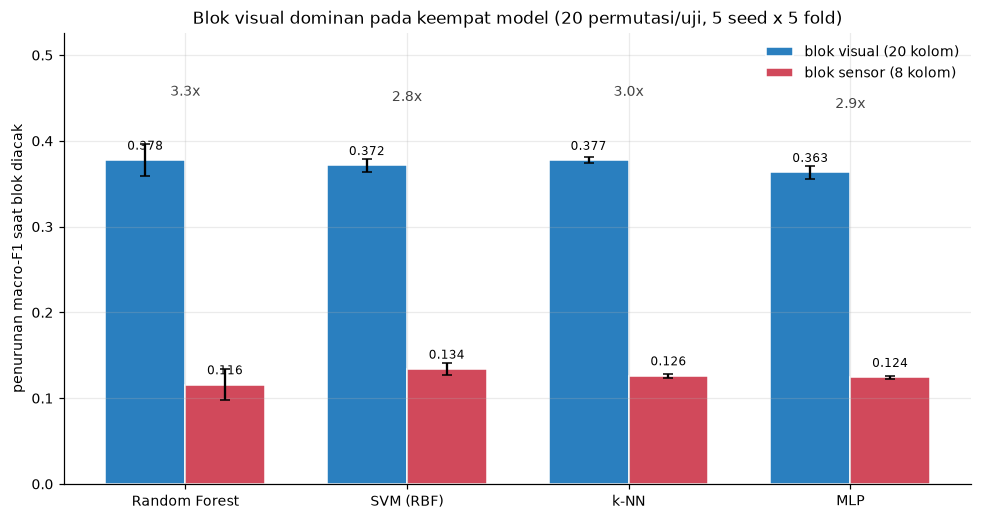

,model,target,drop_mean,drop_sd,n_seed
0,k-NN,sensor,0.1263,0.0023,5
1,k-NN,visual,0.3775,0.0035,5
2,MLP,sensor,0.1245,0.0017,5
3,MLP,visual,0.3634,0.0076,5
4,Random Forest,sensor,0.1159,0.0179,5
5,Random Forest,visual,0.3777,0.0183,5
6,SVM (RBF),sensor,0.1341,0.0072,5
7,SVM (RBF),visual,0.3715,0.0073,5


In [20]:
p = imp_sum.pivot(index="model", columns="target", values="drop_mean").loc[MODEL]
sd = imp_sum.pivot(index="model", columns="target", values="drop_sd").loc[MODEL]

fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(MODEL))
w = 0.36
for k, t in enumerate(["visual", "sensor"]):
    posisi = x + (k - 0.5) * w
    ax.bar(posisi, p[t], w, yerr=sd[t], capsize=3, color=WARNA[t],
           label=f"blok {t} ({len(V) if t == 'visual' else len(S)} kolom)", edgecolor="white")
    for xi, v in zip(posisi, p[t]):
        ax.text(xi, v + 0.012, f"{v:.3f}", ha="center", fontsize=8)
for k, m in enumerate(MODEL):
    ax.annotate(f"{p.loc[m, 'visual'] / p.loc[m, 'sensor']:.1f}x",
                (k, max(p.loc[m]) + 0.075), ha="center", fontsize=9, color="#444444")
ax.set_ylim(0, float((p.visual + sd.visual).max()) + 0.13)
ax.set_xticks(x, [LABEL_MODEL[m] for m in MODEL])
ax.set_ylabel("penurunan macro-F1 saat blok diacak")
ax.legend(frameon=False, loc="upper right")
ax.set_title("Blok visual dominan pada keempat model (20 permutasi/uji, 5 seed x 5 fold)", fontsize=11)
fig.tight_layout()
tampil(fig, "19_importance_blok")
display(imp_sum.assign(model=lambda d: d.model.map(LABEL_MODEL)).round(4))

### 7.1 Konfirmasi arah dengan *drop-one* (F5) — dan jebakan skalanya

Dua metode ini **tidak sebanding besarnya**:

| | permutasi (F5c) | drop-one (F5) |
|---|---|---|
| model dilatih ulang? | **tidak** | **ya**, tanpa blok itu |
| yang diukur | ketergantungan model pada blok | kontribusi blok setelah model beradaptasi |
| orde angka | ~0,1–0,4 | ~0,002–0,04 |

Saat blok visual dibuang dan model dilatih ulang, sensor **menggantikan**
sebagian perannya, jadi selisihnya kecil. Yang boleh disimpulkan hanya
**arahnya**: keduanya sepakat visual > sensor. Rasio di bawah menunjukkan
betapa jauh orde angkanya berbeda.

,permutasi_visual,permutasi_sensor,dropone_visual,dropone_sensor,rasio_visual,rasio_sensor,searah
Random Forest,0.3777,0.1159,0.0382,0.0022,9.8940,52.6663,ya
SVM (RBF),0.3715,0.1341,0.0362,0.0080,10.2633,16.6526,ya
k-NN,0.3775,0.1263,0.0296,0.0055,12.7624,22.8190,ya
MLP,0.3634,0.1245,0.0338,0.0053,10.7564,23.5102,ya


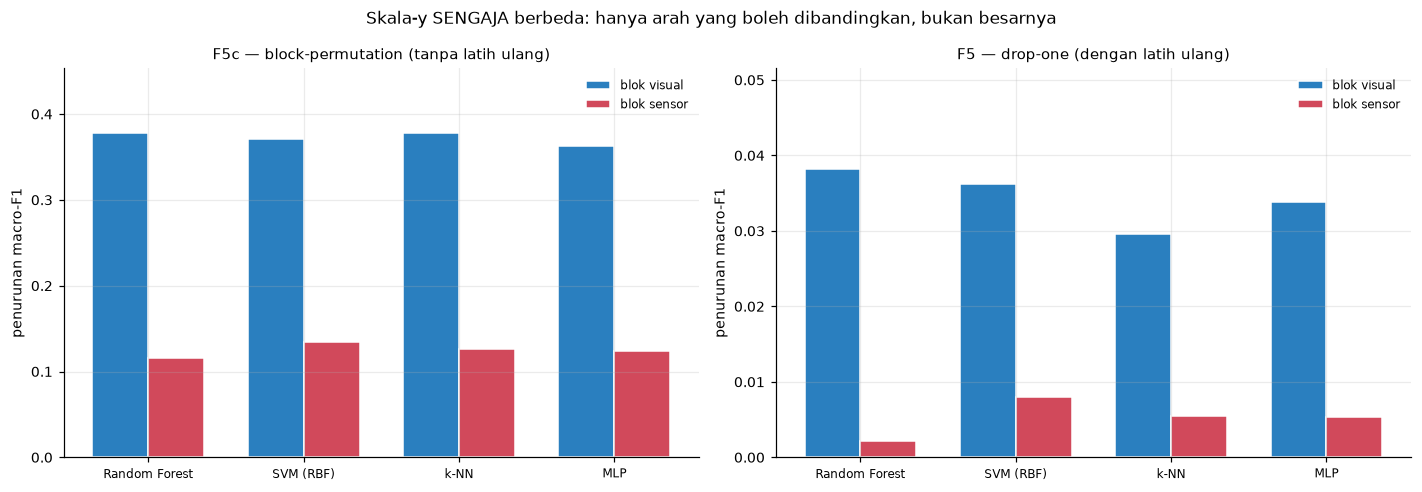

WindowsPath('D:/Documents/S2/Kuliah/261/RFPP/figures/20_permutasi_vs_dropone.png')

In [21]:
do = delta.groupby("model")[["delta_vs_visual", "delta_vs_sensor"]].mean().loc[MODEL]
banding = pd.DataFrame({
    "permutasi_visual": p["visual"],
    "permutasi_sensor": p["sensor"],
    "dropone_visual": do["delta_vs_sensor"],
    "dropone_sensor": do["delta_vs_visual"],
})
banding["rasio_visual"] = banding.permutasi_visual / banding.dropone_visual
banding["rasio_sensor"] = banding.permutasi_sensor / banding.dropone_sensor
banding["searah"] = np.where(
    (banding.permutasi_visual > banding.permutasi_sensor)
    & (banding.dropone_visual > banding.dropone_sensor), "ya", "TIDAK")
banding.index = [LABEL_MODEL[m] for m in banding.index]
display(banding.round(4))
assert (banding.searah == "ya").all(), "arah permutasi dan drop-one bertentangan"

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)
for ax, (kol_v, kol_s, judul) in zip(axes, [
    ("permutasi_visual", "permutasi_sensor", "F5c — block-permutation (tanpa latih ulang)"),
    ("dropone_visual", "dropone_sensor", "F5 — drop-one (dengan latih ulang)"),
]):
    for k, (kol, t) in enumerate([(kol_v, "visual"), (kol_s, "sensor")]):
        posisi = x + (k - 0.5) * w
        ax.bar(posisi, banding[kol], w, color=WARNA[t], label=f"blok {t}", edgecolor="white")
    ax.set_xticks(x, [LABEL_MODEL[m] for m in MODEL], fontsize=8)
    ax.set_title(judul, fontsize=10)
    ax.set_ylabel("penurunan macro-F1")
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylim(0, float(banding.permutasi_visual.max()) * 1.2)
axes[1].set_ylim(0, float(banding.dropone_visual.max()) * 1.35)
fig.suptitle("Skala-y SENGAJA berbeda: hanya arah yang boleh dibandingkan, bukan besarnya", fontsize=11)
fig.tight_layout()
tampil(fig, "20_permutasi_vs_dropone")

### 7.2 Top-10 per fitur (pelengkap, bukan jawaban utama)

Peringkat per-fitur **tidak stabil antar model** — jangan menulis "fitur X adalah
penanda pembusukan" dari satu model. Biru = fitur visual, merah = kanal sensor.
Perhatikan ordenya jauh di bawah penurunan blok: itu efek redundansi (§3.4).

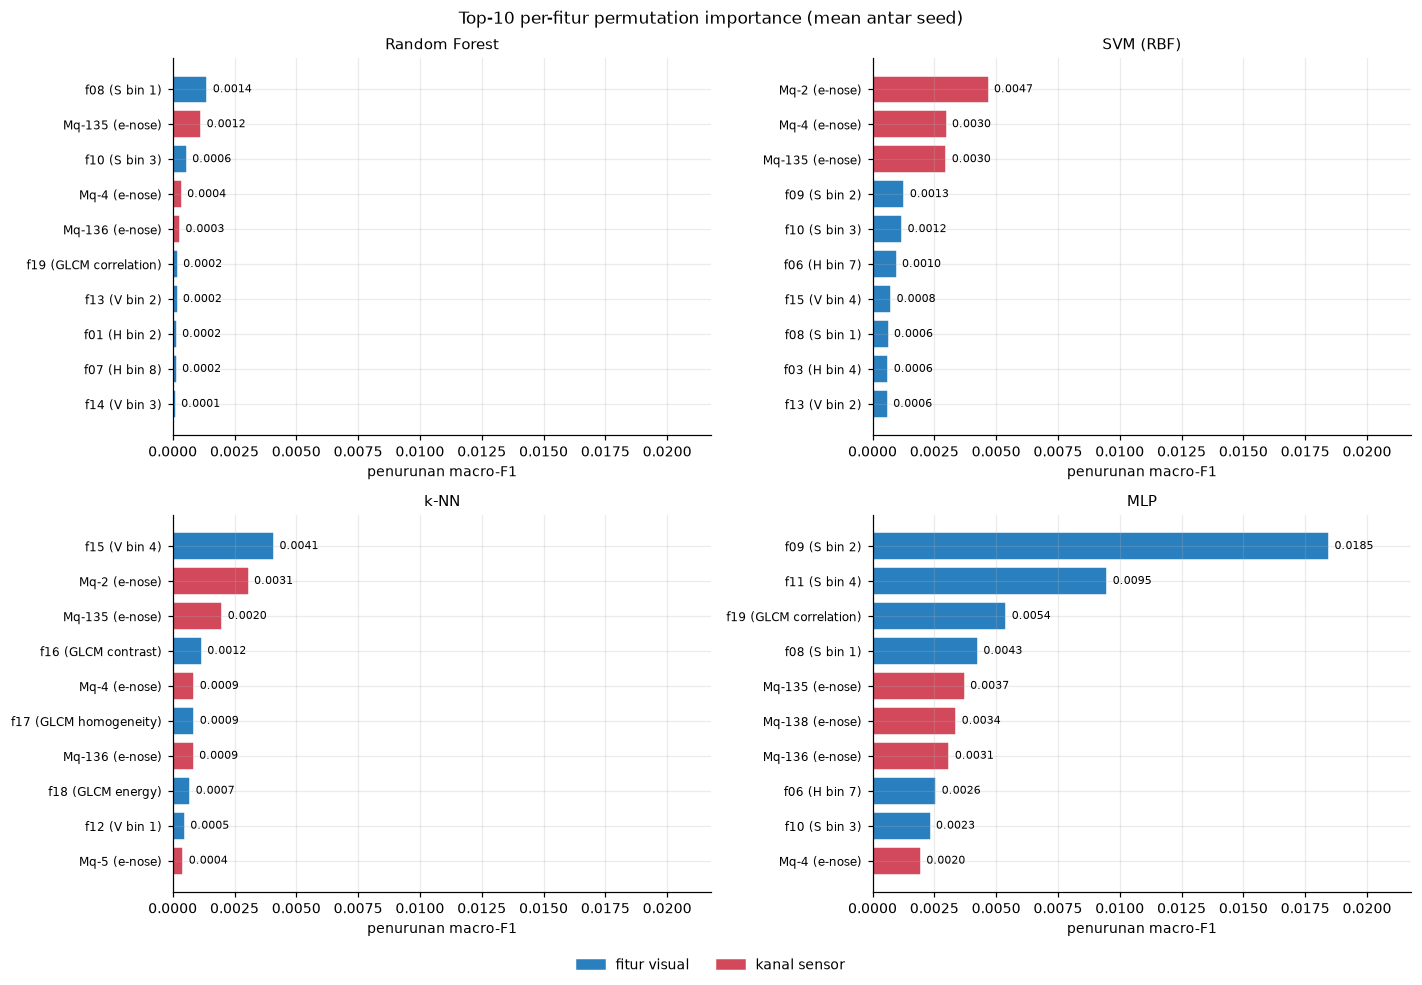

Fitur yang masuk top-10 di SEMUA model: ['Mq-135', 'Mq-4']
Penurunan per-fitur maksimum : 0.0528
Penurunan per-blok maksimum  : 0.4727


In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
xmax = float(imp_top.drop_mean.max()) * 1.18
for ax, m in zip(axes.ravel(), MODEL):
    d = imp_top[imp_top.model == m].sort_values("peringkat")
    warna = [WARNA["visual"] if t in V else WARNA["sensor"] for t in d.target]
    ax.barh(range(len(d)), d.drop_mean, color=warna, edgecolor="white")
    ax.set_yticks(range(len(d)), [f"{t} ({NAMA_FITUR.get(t, 'e-nose')})" for t in d.target], fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(0, xmax)
    ax.set_xlabel("penurunan macro-F1")
    ax.set_title(LABEL_MODEL[m], fontsize=10)
    for yi, v in enumerate(d.drop_mean):
        ax.text(v + xmax * 0.01, yi, f"{v:.4f}", va="center", fontsize=7)
handles = [Rectangle((0, 0), 1, 1, color=WARNA["visual"]),
           Rectangle((0, 0), 1, 1, color=WARNA["sensor"])]
fig.legend(handles, ["fitur visual", "kanal sensor"], loc="lower center", ncol=2, frameon=False)
fig.suptitle("Top-10 per-fitur permutation importance (mean antar seed)", fontsize=11)
fig.tight_layout(rect=(0, 0.03, 1, 1))
tampil(fig, "21_top10_per_fitur")

irisan = [set(imp_top[imp_top.model == m].target) for m in MODEL]
print("Fitur yang masuk top-10 di SEMUA model:", sorted(set.intersection(*irisan)) or "(tidak ada)")
print(f"Penurunan per-fitur maksimum : {float(imp_feat.drop_mean.max()):.4f}")
print(f"Penurunan per-blok maksimum  : {float(imp.drop_mean.max()):.4f}")

## 8. Batas klaim yang wajib ditulis di laporan

Tanpa bagian ini, angka-angka di atas **menyesatkan**.

**Yang boleh diklaim**

1. Pada protokol ini, fused 28-D mengalahkan kedua baseline unimodal yang memakai
   baris berpasangan identik: vs sensor **20/20** seed×model positif; vs visual
   **19/20** (satu negatif: MLP seed 44). Uji tanda satu sisi p = 0,031 untuk
   RF/SVM/k-NN, p = 0,188 untuk MLP — dengan n = 5 seed, ini bukti lemah.
2. Penskalaan setelah concatenation penting untuk model berbasis jarak
   (k-NN dan SVM turun tanpa itu).
3. Blok visual dominan atas blok sensor, konsisten arah antara block-permutation
   dan drop-one pada keempat model.
4. Saat modalitas bertentangan, model lebih sering mengikuti visual; pada arah
   *visual segar ↔ sensor busuk* sebagian besar pasangan tetap **diterima**
   meskipun gas menunjukkan busuk → risiko keamanan pangan.

**Yang TIDAK boleh diklaim**

1. **"Akurasi deteksi pembusukan 99%."** Skor absolut 0,95–0,998 adalah performa
   pada interpolasi temporal di dalam satu trajektori, bukan deteksi di dunia nyata.
2. **Generalisasi antar objek.** Kedua dataset adalah satu trajektori dengan
   label = segmen waktu; tidak ada replikasi objek independen di modalitas mana pun.
3. **Split blok waktu menghilangkan kebocoran waktu.** Ia hanya mencegah frame
   bersebelahan berada di latih dan uji sekaligus; blok yang berjauhan tetap
   berkorelasi kuat karena perubahan warna berlangsung lambat. Uji *embargo*
   (membuang blok di sekitar batas fold) **tidak dijalankan**.
4. **Konfound waktu = label.** Warna daging berubah sepanjang waktu, dan label
   juga berubah sepanjang waktu. Model bisa memisahkan kelas memakai petunjuk
   waktu/pencahayaan, bukan pembusukan itu sendiri.
5. **Angka probe adalah akurasi.** Pasangan diskordan tidak punya ground truth;
   yang dilaporkan hanya kesepakatan dan proporsi penolakan.
6. **Confidence antar model sebanding.** SVM memakai |margin|, lainnya max_proba.
7. **Besarnya permutasi ≈ besarnya drop-one.** Hanya arah yang sebanding (§7.1).
8. **Peringkat per-fitur adalah penanda pembusukan yang universal.** Tidak stabil
   antar model, dan ordenya di bawah penurunan blok karena redundansi.
9. **Fusi memperbaiki FN menjadi nol = aman.** `FN = 0` di sini adalah efek
   langit-langit dataset, bukan jaminan keamanan pangan.

**Keterbatasan protokol yang masih terbuka**

* Blok batas **sensor** tidak dibuang, sedangkan blok batas **visual** dibuang
  (§2.1). Bukan kebocoran antar-fold, tetapi ambiguitas label di menit transisi.
* Domain gap antar trajektori / antar negara / antar tahun belum diuji dan harus
  dinyatakan sebagai keterbatasan, bukan diasumsikan tidak ada.

In [23]:
print(f"{len(TERSIMPAN)} gambar tersimpan di {FIG.relative_to(ROOT)}/:")
for p in TERSIMPAN:
    print(f"  {p.name:<34} {p.stat().st_size / 1024:7.1f} KB")

ringkas = pd.DataFrame([
    {"berkas": f.name, "baris": len(pd.read_csv(f))}
    for f in sorted(RES.glob("*.csv"))
])
display(ringkas)
print("\nSemua angka di notebook ini berasal dari results/ dan cache/ — tidak ada pelatihan ulang.")

21 gambar tersimpan di figures/:
  01_sensor_trajektori.png             279.4 KB
  02_sensor_boxplot.png                 99.2 KB
  03_sensor_korelasi.png                95.2 KB
  04_visual_trajektori.png              71.8 KB
  05_visual_contoh_mentah.png         2825.5 KB
  06_visual_roi.png                   1807.1 KB
  07_visual_fitur_waktu.png            178.2 KB
  08_histogram_per_kelas.png            78.1 KB
  09_visual_korelasi.png                53.6 KB
  10_ukuran_fold.png                    85.7 KB
  11_composisi_uji.png                  28.4 KB
  12_macro_f1_per_set.png               51.5 KB
  13_heatmap_metrik.png                142.9 KB
  14_selisih_berpasangan.png           110.7 KB
  15_efek_scaling.png                   38.1 KB
  16_confusion_matrix.png              185.9 KB
  17_probe_diskordan.png                75.5 KB
  18_probe_confidence.png               41.2 KB
  19_importance_blok.png                50.5 KB
  20_permutasi_vs_dropone.png           52.5 KB
  21_to

,berkas,baris
0,confusion.csv,14
1,importance.csv,200
2,importance_per_feature.csv,2800
3,importance_summary.csv,8
4,importance_top10.csv,40
5,metrics.csv,350
6,paired_delta.csv,20
7,probe.csv,200
8,probe_summary.csv,8
9,summary.csv,14



Semua angka di notebook ini berasal dari results/ dan cache/ — tidak ada pelatihan ulang.
